# Tugas Sesi 07 — Studi Komparatif Generative Models (AE, Sparse AE, VAE, GAN, DCGAN, DDPM)

**Nama:** Kevin Sukias K
**NIM:** 2802526416

Dataset: Fashion-MNIST (train + test bawaan digabung = 70.000 image), split stratified 80/10/10.
Semua metrik numerik dihitung pada **test set**.

| Kode | Model | Laten |
|---|---|---|
| M1 | Vanilla Autoencoder (MLP) | 64 |
| M2 | Sparse Autoencoder (MLP, penalti L1 pada hidden 256) | 64 (bottleneck) / 256 (sparse) |
| M3 | Variational Autoencoder (MLP) | 64 |
| M4 | Vanilla GAN (MLP / fully connected) | 100 (prior noise) |
| M5 | DCGAN (konvolusional) | 100 (prior noise) |
| M6 | DDPM (U-Net kecil, T = 500) | 28×28 |
| P  | MLP Classifier 784→256→64→10 + eksperimen batasan (Bagian 2 soal) | 64 |

Catatan: semua eksperimen dijalankan di **CPU** (2 core), sehingga epoch dan ukuran model dibuat sederhana.
Setiap model disimpan ke `checkpoints/`; kalau checkpoint sudah ada, training dilewati dan bobot + log di-load ulang.

## 0. Setup

In [1]:
import os, json, time, math, random, platform
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
import torchvision
from torchvision.datasets import FashionMNIST
from torchvision.utils import make_grid

from sklearn.model_selection import train_test_split
from skimage.metrics import structural_similarity
from scipy import linalg
from pytorch_fid.inception import InceptionV3

SEED = 42
QUICK = os.environ.get("QUICK", "0") == "1"   # smoke test: epoch & sampel dikecilkan

CFG = {
    "seed": SEED, "dataset": "FashionMNIST", "split": "80/10/10 stratified",
    "batch_size": 128, "latent_ae": 64, "hidden": 256, "z_gan": 100,
    "epochs": {"ae": 20, "sae": 20, "vae": 20, "mlp": 15, "frozen_dec": 20,
               "gan": 40, "dcgan": 15, "ddpm": 10},
    "lr": {"ae": 1e-3, "sae": 1e-3, "vae": 1e-3, "mlp": 1e-3, "frozen_dec": 1e-3,
           "gan": 2e-4, "dcgan": 2e-4, "ddpm": 2e-4},
    "sparse_lambda": 1e-4,          # lambda * ||h||_1 (sum per sampel, mean per batch)
    "ddpm_T": 500, "ddpm_beta": [1e-4, 0.04], "ddpm_channels": 32, "ema": 0.999,
    "n_fid": 2000, "latency_batch": 64,
}
if QUICK:
    CFG["epochs"] = {k: 1 for k in CFG["epochs"]}
    CFG["n_fid"] = 200
    CFG["ddpm_T"] = 50

torch.set_num_threads(os.cpu_count())
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

OUT_DIR = Path("outputs"); FIG_DIR = OUT_DIR / "figures"; CKPT_DIR = Path("checkpoints")
for d in (OUT_DIR, FIG_DIR, CKPT_DIR):
    d.mkdir(parents=True, exist_ok=True)

ENV = {"python": platform.python_version(), "torch": torch.__version__,
       "torchvision": torchvision.__version__, "device": str(device),
       "cpu": platform.processor() or platform.machine(), "threads": torch.get_num_threads()}
print(ENV); print("QUICK =", QUICK)

{'python': '3.13.18', 'torch': '2.15.0+cu132', 'torchvision': '0.29.2+cu132', 'device': 'cpu', 'cpu': 'x86_64', 'threads': 2}
QUICK = False


In [2]:
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()

## 1. Dataset dan split 80/10/10

Split bawaan Fashion-MNIST (60k/10k) digabung, lalu dibagi ulang secara stratified supaya proporsi 10 kelas sama di tiap split.
Image disimpan di RAM sebagai tensor `[0, 1]`. Model berbasis `tanh` (GAN, DCGAN, DDPM) memakai skala `[-1, 1]`.

In [3]:
tr = FashionMNIST("./data", train=True, download=True)
te = FashionMNIST("./data", train=False, download=True)
X_all = torch.cat([tr.data, te.data]).float().div(255.).unsqueeze(1)   # [70000, 1, 28, 28]
y_all = torch.cat([tr.targets, te.targets])
CLASS_NAMES = tr.classes

idx = np.arange(len(y_all))
train_idx, tmp_idx = train_test_split(idx, test_size=0.20, stratify=y_all, random_state=SEED)
val_idx, test_idx = train_test_split(tmp_idx, test_size=0.50, stratify=y_all[tmp_idx], random_state=SEED)
assert not (set(train_idx) & set(val_idx)) and not (set(train_idx) & set(test_idx)) and not (set(val_idx) & set(test_idx))

X_tr, y_tr = X_all[train_idx], y_all[train_idx]
X_va, y_va = X_all[val_idx], y_all[val_idx]
X_te, y_te = X_all[test_idx], y_all[test_idx]
print(f"train {len(X_tr)} | val {len(X_va)} | test {len(X_te)}")

def make_loader(X, y, shuffle):
    g = torch.Generator().manual_seed(SEED)
    return DataLoader(TensorDataset(X, y), batch_size=CFG["batch_size"], shuffle=shuffle, generator=g)

train_loader = make_loader(X_tr, y_tr, True)
val_loader = make_loader(X_va, y_va, False)
test_loader = make_loader(X_te, y_te, False)

with open(OUT_DIR / "config.json", "w") as f:
    json.dump({"config": CFG, "env": ENV}, f, indent=2)

train 56000 | val 7000 | test 7000


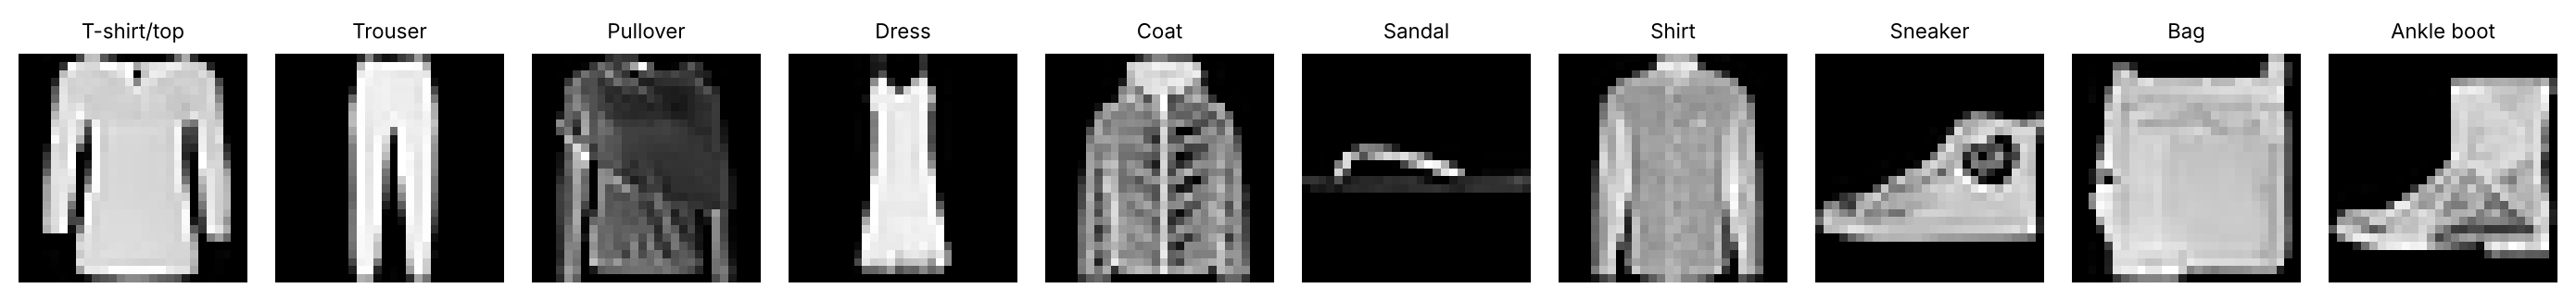

In [4]:
fig, axes = plt.subplots(1, 10, figsize=(14, 1.9))
for c, ax in enumerate(axes):
    ax.imshow(X_tr[y_tr == c][0, 0], cmap="gray"); ax.set_title(CLASS_NAMES[c], fontsize=8); ax.axis("off")
plt.tight_layout(); plt.savefig(FIG_DIR / "sample_per_class.png", dpi=150); plt.show()

## 2. Fungsi bantu: training loop, checkpoint, metrik

In [5]:
HIST = {}      # name -> list of dict per epoch

def count_params(m):
    return sum(p.numel() for p in m.parameters())

def fit(name, modules, train_step, epochs, val_fn=None, on_epoch_end=None):
    """
    Training loop generik.
    modules     : dict nama -> nn.Module (disimpan ke checkpoint)
    train_step  : f(x, y) -> dict loss (float) untuk satu batch
    val_fn      : f() -> float (val loss), opsional
    Kalau checkpoint ada, training dilewati dan log di-load.
    """
    ck, hp = CKPT_DIR / f"{name}.pt", CKPT_DIR / f"{name}_history.json"
    if ck.exists() and hp.exists():
        state = torch.load(ck, map_location=device)
        for k, m in modules.items():
            m.load_state_dict(state[k])
        HIST[name] = json.load(open(hp))
        print(f"[{name}] checkpoint di-load ({len(HIST[name])} epoch)")
        return HIST[name]

    set_seed()
    hist = []
    for ep in range(1, epochs + 1):
        for m in modules.values():
            m.train()
        t0, sums, n, iter_main = time.time(), {}, 0, []
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            logs = train_step(x, y)
            for k, v in logs.items():
                sums[k] = sums.get(k, 0.0) + v * len(x)
            iter_main.append(list(logs.values())[0])
            n += len(x)
        if on_epoch_end:
            on_epoch_end()
        row = {"epoch": ep, "time_s": time.time() - t0, **{k: v / n for k, v in sums.items()},
               "iter_std_main": float(np.std(iter_main))}
        if val_fn:
            for m in modules.values():
                m.eval()
            row["val_loss"] = val_fn()
        hist.append(row)
        print(f"[{name}] ep {ep:02d} | " + " | ".join(f"{k} {v:.4f}" for k, v in row.items() if k != "epoch"))
    torch.save({k: m.state_dict() for k, m in modules.items()}, ck)
    json.dump(hist, open(hp, "w"), indent=1)
    HIST[name] = hist
    return hist

@torch.no_grad()
def recon_metrics(x, xh):
    """MSE (rata-rata piksel), PSNR (rata-rata per image) dan SSIM (rata-rata per image), data range [0,1]."""
    x, xh = x.cpu().numpy()[:, 0], xh.clamp(0, 1).cpu().numpy()[:, 0]
    mse_i = ((x - xh) ** 2).reshape(len(x), -1).mean(1)
    psnr = 10 * np.log10(1.0 / np.maximum(mse_i, 1e-10))
    ssim = [structural_similarity(a, b, data_range=1.0) for a, b in zip(x, xh)]
    return {"test_mse": float(mse_i.mean()), "test_psnr": float(psnr.mean()), "test_ssim": float(np.mean(ssim))}

@torch.no_grad()
def batched(fn, X, bs=500):
    return torch.cat([fn(X[i:i + bs].to(device)).cpu() for i in range(0, len(X), bs)])

@torch.no_grad()
def latency_ms(fn, repeat=20, warmup=3):
    for _ in range(warmup):
        fn()
    t0 = time.perf_counter()
    for _ in range(repeat):
        fn()
    return (time.perf_counter() - t0) / repeat * 1000

def show_grid(ax, imgs, nrow, title=None):
    g = make_grid(imgs.clamp(0, 1), nrow=nrow, padding=2, pad_value=1.0)
    ax.imshow(g[0], cmap="gray", vmin=0, vmax=1); ax.axis("off")
    if title:
        ax.set_title(title, fontsize=10)

to01 = lambda x: (x + 1) / 2         # [-1,1] -> [0,1]
to11 = lambda x: x * 2 - 1           # [0,1]  -> [-1,1]

## 3. M1 & M2 — Vanilla AE dan Sparse AE

Arsitektur keduanya identik: encoder 784 → 256 (ReLU) → 64 (linear), decoder 64 → 256 (ReLU) → 784 (Sigmoid).

- Vanilla AE: $\mathcal{L} = \frac{1}{N}\sum \lVert x - \hat{x} \rVert_2^2$ (MSE)
- Sparse AE: $\mathcal{L} = \text{MSE} + \lambda \lVert h \rVert_1$, dengan $h \in \mathbb{R}^{256}$ adalah aktivasi hidden layer encoder dan $\lambda = 10^{-4}$.

Jadi Sparse AE punya bottleneck 64, sementara penalti sparsity diterapkan pada representasi 256-dim.

In [6]:
class AE(nn.Module):
    def __init__(self, latent=64, hidden=256):
        super().__init__()
        self.enc1 = nn.Linear(784, hidden)
        self.enc2 = nn.Linear(hidden, latent)
        self.dec = nn.Sequential(nn.Linear(latent, hidden), nn.ReLU(), nn.Linear(hidden, 784), nn.Sigmoid())
    def encode(self, x, return_h=False):
        h = F.relu(self.enc1(x.view(len(x), -1)))
        z = self.enc2(h)
        return (z, h) if return_h else z
    def decode(self, z):
        return self.dec(z).view(-1, 1, 28, 28)
    def forward(self, x):
        return self.decode(self.encode(x))

def train_ae(name, sparse_lambda=0.0):
    set_seed()
    model = AE(CFG["latent_ae"], CFG["hidden"]).to(device)
    opt = torch.optim.Adam(model.parameters(), lr=CFG["lr"][name])
    def step(x, y):
        z, h = model.encode(x, return_h=True)
        rec = F.mse_loss(model.decode(z), x)
        l1 = h.abs().sum(1).mean()
        loss = rec + sparse_lambda * l1
        opt.zero_grad(); loss.backward(); opt.step()
        out = {"loss": loss.item(), "recon": rec.item()}
        if sparse_lambda > 0:
            out["l1_term"] = (sparse_lambda * l1).item()
        return out
    def val():
        with torch.no_grad():
            return float(np.mean([F.mse_loss(model(x.to(device)), x.to(device)).item() for x, _ in val_loader]))
    fit(name, {"model": model}, step, CFG["epochs"][name], val)
    return model.eval()

ae = train_ae("ae")
sae = train_ae("sae", CFG["sparse_lambda"])

[ae] ep 01 | time_s 1.9927 | loss 0.0321 | recon 0.0321 | iter_std_main 0.0230 | val_loss 0.0187


[ae] ep 02 | time_s 1.9911 | loss 0.0167 | recon 0.0167 | iter_std_main 0.0013 | val_loss 0.0152


[ae] ep 03 | time_s 6.7581 | loss 0.0140 | recon 0.0140 | iter_std_main 0.0010 | val_loss 0.0130


[ae] ep 04 | time_s 2.1730 | loss 0.0124 | recon 0.0124 | iter_std_main 0.0008 | val_loss 0.0119


[ae] ep 05 | time_s 2.5374 | loss 0.0113 | recon 0.0113 | iter_std_main 0.0007 | val_loss 0.0110


[ae] ep 06 | time_s 2.7234 | loss 0.0105 | recon 0.0105 | iter_std_main 0.0007 | val_loss 0.0106


... (30 outputs left out)

[sae] ep 17 | time_s 2.6887 | loss 0.0122 | recon 0.0114 | l1_term 0.0008 | iter_std_main 0.0007 | val_loss 0.0115


[sae] ep 18 | time_s 2.5051 | loss 0.0121 | recon 0.0112 | l1_term 0.0008 | iter_std_main 0.0007 | val_loss 0.0114


[sae] ep 19 | time_s 3.0612 | loss 0.0119 | recon 0.0111 | l1_term 0.0008 | iter_std_main 0.0007 | val_loss 0.0113


[sae] ep 20 | time_s 2.9191 | loss 0.0118 | recon 0.0110 | l1_term 0.0008 | iter_std_main 0.0007 | val_loss 0.0111


## 4. M3 — Variational Autoencoder

Encoder 784 → 256 → ($\mu$, $\log\sigma^2$) ∈ ℝ⁶⁴, reparameterization $z = \mu + \sigma \odot \epsilon$, decoder sama dengan AE.

$\mathcal{L}_{VAE} = \underbrace{\text{BCE}(x, \hat{x})}_{\text{sum per image}} + D_{KL}\big(\mathcal{N}(\mu, \sigma^2)\,\|\,\mathcal{N}(0, I)\big)$, dengan
$D_{KL} = -\tfrac{1}{2}\sum(1 + \log\sigma^2 - \mu^2 - \sigma^2)$. Untuk metrik rekonstruksi dipakai $z = \mu$ (deterministik).

In [7]:
class VAE(nn.Module):
    def __init__(self, latent=64, hidden=256):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(784, hidden), nn.ReLU())
        self.mu = nn.Linear(hidden, latent)
        self.logvar = nn.Linear(hidden, latent)
        self.dec = nn.Sequential(nn.Linear(latent, hidden), nn.ReLU(), nn.Linear(hidden, 784), nn.Sigmoid())
        self.latent = latent
    def encode(self, x):
        h = self.enc(x.view(len(x), -1))
        return self.mu(h), self.logvar(h)
    def decode(self, z):
        return self.dec(z).view(-1, 1, 28, 28)
    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)
        return self.decode(z), mu, logvar
    def reconstruct(self, x):
        return self.decode(self.encode(x)[0])

def vae_loss(x, xh, mu, logvar):
    bce = F.binary_cross_entropy(xh, x, reduction="sum") / len(x)
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp()) / len(x)
    return bce, kl

set_seed()
vae = VAE(CFG["latent_ae"], CFG["hidden"]).to(device)
opt_vae = torch.optim.Adam(vae.parameters(), lr=CFG["lr"]["vae"])
def vae_step(x, y):
    xh, mu, logvar = vae(x)
    bce, kl = vae_loss(x, xh, mu, logvar)
    loss = bce + kl
    opt_vae.zero_grad(); loss.backward(); opt_vae.step()
    return {"loss": loss.item(), "recon_bce": bce.item(), "kl": kl.item()}
def vae_val():
    with torch.no_grad():
        out = []
        for x, _ in val_loader:
            x = x.to(device); xh, mu, lv = vae(x); b, k = vae_loss(x, xh, mu, lv); out.append((b + k).item())
        return float(np.mean(out))
fit("vae", {"model": vae}, vae_step, CFG["epochs"]["vae"], vae_val)
vae.eval();

[vae] ep 01 | time_s 2.6245 | loss 299.6962 | recon_bce 285.0389 | kl 14.6573 | iter_std_main 43.5111 | val_loss 274.1894


[vae] ep 02 | time_s 2.8709 | loss 266.8537 | recon_bce 250.6617 | kl 16.1920 | iter_std_main 7.7508 | val_loss 261.9964


[vae] ep 03 | time_s 3.1165 | loss 257.8073 | recon_bce 242.5643 | kl 15.2430 | iter_std_main 6.8712 | val_loss 255.4420


[vae] ep 04 | time_s 2.8784 | loss 252.6872 | recon_bce 237.9050 | kl 14.7822 | iter_std_main 6.7248 | val_loss 251.6509


[vae] ep 05 | time_s 2.8392 | loss 249.8539 | recon_bce 235.0731 | kl 14.7808 | iter_std_main 6.8844 | val_loss 249.3589


[vae] ep 06 | time_s 2.9446 | loss 248.0038 | recon_bce 233.2263 | kl 14.7775 | iter_std_main 6.8699 | val_loss 248.4086


... (10 outputs left out)

[vae] ep 17 | time_s 2.8881 | loss 242.3331 | recon_bce 226.4709 | kl 15.8621 | iter_std_main 6.8903 | val_loss 243.3812


[vae] ep 18 | time_s 3.0118 | loss 242.1182 | recon_bce 226.2469 | kl 15.8713 | iter_std_main 6.7880 | val_loss 243.0170


[vae] ep 19 | time_s 2.8887 | loss 242.0229 | recon_bce 226.0897 | kl 15.9333 | iter_std_main 6.6017 | val_loss 242.9247


[vae] ep 20 | time_s 2.9277 | loss 241.8015 | recon_bce 225.8683 | kl 15.9332 | iter_std_main 6.4509 | val_loss 242.8089


## 5. M4 — Vanilla GAN (MLP)

Generator 100 → 256 → 512 → 1024 → 784 (LeakyReLU 0.2, output tanh), Discriminator 784 → 512 → 256 → 1 (LeakyReLU 0.2). Tanpa BatchNorm/Dropout supaya benar-benar "vanilla".

$\min_G \max_D \; \mathbb{E}_{x}[\log D(x)] + \mathbb{E}_{z}[\log(1 - D(G(z)))]$. Generator memakai bentuk non-saturating $\mathcal{L}_G = -\mathbb{E}_z[\log D(G(z))]$. Adam lr 2e-4, $\beta_1 = 0.5$.

In [8]:
class MLPGen(nn.Module):
    def __init__(self, z=100):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(z, 256), nn.LeakyReLU(0.2), nn.Linear(256, 512), nn.LeakyReLU(0.2),
            nn.Linear(512, 1024), nn.LeakyReLU(0.2), nn.Linear(1024, 784), nn.Tanh())
    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)

class MLPDisc(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(784, 512), nn.LeakyReLU(0.2), nn.Linear(512, 256), nn.LeakyReLU(0.2), nn.Linear(256, 1))
    def forward(self, x):
        return self.net(x.view(len(x), -1)).squeeze(1)

class DCGen(nn.Module):
    def __init__(self, z=100):
        super().__init__()
        self.fc = nn.Sequential(nn.Linear(z, 128 * 7 * 7, bias=False), nn.BatchNorm1d(128 * 7 * 7), nn.ReLU())
        self.net = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False), nn.BatchNorm2d(64), nn.ReLU(),   # 14x14
            nn.ConvTranspose2d(64, 1, 4, 2, 1), nn.Tanh())                                     # 28x28
    def forward(self, z):
        return self.net(self.fc(z).view(-1, 128, 7, 7))

class DCDisc(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 64, 4, 2, 1), nn.LeakyReLU(0.2),                              # 14x14
            nn.Conv2d(64, 128, 4, 2, 1, bias=False), nn.BatchNorm2d(128), nn.LeakyReLU(0.2),  # 7x7
            nn.Flatten(), nn.Linear(128 * 7 * 7, 1))
    def forward(self, x):
        return self.net(x).squeeze(1)

def dcgan_init(m):
    # inisialisasi N(0, 0.02) sesuai Radford et al. (2016)
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d, nn.Linear)):
        nn.init.normal_(m.weight, 0.0, 0.02)
        if m.bias is not None:
            nn.init.zeros_(m.bias)
    elif isinstance(m, (nn.BatchNorm2d, nn.BatchNorm1d)):
        nn.init.normal_(m.weight, 1.0, 0.02); nn.init.zeros_(m.bias)

def train_gan(name, G, D):
    set_seed()
    G, D = G.to(device), D.to(device)
    oG = torch.optim.Adam(G.parameters(), lr=CFG["lr"][name], betas=(0.5, 0.999))
    oD = torch.optim.Adam(D.parameters(), lr=CFG["lr"][name], betas=(0.5, 0.999))
    bce = nn.BCEWithLogitsLoss()
    fixed_z = torch.randn(16, CFG["z_gan"], generator=torch.Generator().manual_seed(SEED)).to(device)
    snaps = []
    def step(x, y):
        x = to11(x); b = len(x)
        z = torch.randn(b, CFG["z_gan"], device=device)
        fake = G(z)
        # --- update D ---
        d_real, d_fake = D(x), D(fake.detach())
        lD = bce(d_real, torch.ones_like(d_real)) + bce(d_fake, torch.zeros_like(d_fake))
        oD.zero_grad(); lD.backward(); oD.step()
        # --- update G (non-saturating) ---
        d_gen = D(fake)
        lG = bce(d_gen, torch.ones_like(d_gen))
        oG.zero_grad(); lG.backward(); oG.step()
        return {"loss_G": lG.item(), "loss_D": lD.item(),
                "D_x": torch.sigmoid(d_real).mean().item(), "D_Gz": torch.sigmoid(d_fake).mean().item()}
    def snap():
        G.eval()
        with torch.no_grad():
            snaps.append(to01(G(fixed_z)).cpu())
        G.train()
    fit(name, {"G": G, "D": D}, step, CFG["epochs"][name], on_epoch_end=snap)
    if snaps:
        torch.save(torch.stack(snaps), CKPT_DIR / f"{name}_snaps.pt")
    return G.eval(), D.eval()

G_gan, D_gan = train_gan("gan", MLPGen(CFG["z_gan"]), MLPDisc())

[gan] ep 01 | time_s 8.2624 | loss_G 1.1160 | loss_D 0.9552 | D_x 0.7910 | D_Gz 0.4718 | iter_std_main 0.2881


[gan] ep 02 | time_s 8.7005 | loss_G 1.8323 | loss_D 0.9056 | D_x 0.7123 | D_Gz 0.3519 | iter_std_main 0.3750


[gan] ep 03 | time_s 8.8775 | loss_G 2.0935 | loss_D 0.8923 | D_x 0.7106 | D_Gz 0.3253 | iter_std_main 0.4409


[gan] ep 04 | time_s 8.1216 | loss_G 1.8324 | loss_D 0.9275 | D_x 0.6873 | D_Gz 0.3300 | iter_std_main 0.4260


[gan] ep 05 | time_s 8.4180 | loss_G 1.3955 | loss_D 1.0988 | D_x 0.6229 | D_Gz 0.3849 | iter_std_main 0.2863


[gan] ep 06 | time_s 8.0665 | loss_G 1.3206 | loss_D 1.1202 | D_x 0.6121 | D_Gz 0.3960 | iter_std_main 0.2500


... (30 outputs left out)

[gan] ep 37 | time_s 7.6147 | loss_G 0.8596 | loss_D 1.3286 | D_x 0.5276 | D_Gz 0.4723 | iter_std_main 0.0628


[gan] ep 38 | time_s 8.3804 | loss_G 0.8580 | loss_D 1.3275 | D_x 0.5284 | D_Gz 0.4723 | iter_std_main 0.0616


[gan] ep 39 | time_s 8.4362 | loss_G 0.8521 | loss_D 1.3316 | D_x 0.5267 | D_Gz 0.4742 | iter_std_main 0.0622


[gan] ep 40 | time_s 8.2416 | loss_G 0.8546 | loss_D 1.3317 | D_x 0.5264 | D_Gz 0.4737 | iter_std_main 0.0607


## 6. M5 — DCGAN

Prinsip DCGAN (Radford et al., 2016): tanpa pooling (strided conv / transposed conv), BatchNorm di G dan D (kecuali layer input D & output G), ReLU di G, LeakyReLU di D, inisialisasi $\mathcal{N}(0, 0.02)$. Loss dan optimizer sama dengan Vanilla GAN.

In [9]:
_G, _D = DCGen(CFG["z_gan"]), DCDisc()
_G.apply(dcgan_init); _D.apply(dcgan_init)
G_dc, D_dc = train_gan("dcgan", _G, _D)

[dcgan] ep 01 | time_s 61.0561 | loss_G 2.3227 | loss_D 0.4573 | D_x 0.8238 | D_Gz 0.1799 | iter_std_main 0.7696


[dcgan] ep 02 | time_s 65.0631 | loss_G 2.0924 | loss_D 0.4662 | D_x 0.8153 | D_Gz 0.1812 | iter_std_main 0.5900


[dcgan] ep 03 | time_s 68.0368 | loss_G 1.7600 | loss_D 0.6596 | D_x 0.7488 | D_Gz 0.2483 | iter_std_main 0.5757


[dcgan] ep 04 | time_s 61.9063 | loss_G 1.5449 | loss_D 0.7794 | D_x 0.7092 | D_Gz 0.2892 | iter_std_main 0.4985


[dcgan] ep 05 | time_s 71.5081 | loss_G 1.4805 | loss_D 0.8204 | D_x 0.6960 | D_Gz 0.3030 | iter_std_main 0.4605


[dcgan] ep 06 | time_s 71.6690 | loss_G 1.4874 | loss_D 0.8164 | D_x 0.6967 | D_Gz 0.3025 | iter_std_main 0.4327


... (5 outputs left out)

[dcgan] ep 12 | time_s 61.6656 | loss_G 1.4520 | loss_D 0.8688 | D_x 0.6829 | D_Gz 0.3168 | iter_std_main 0.3677


[dcgan] ep 13 | time_s 67.9199 | loss_G 1.4693 | loss_D 0.8866 | D_x 0.6806 | D_Gz 0.3195 | iter_std_main 0.4201


[dcgan] ep 14 | time_s 65.7368 | loss_G 1.4538 | loss_D 0.9420 | D_x 0.6710 | D_Gz 0.3284 | iter_std_main 0.5352


[dcgan] ep 15 | time_s 69.5266 | loss_G 1.4617 | loss_D 0.8800 | D_x 0.6807 | D_Gz 0.3194 | iter_std_main 0.3697


## 7. M6 — DDPM

Forward process $q(x_t \mid x_0) = \mathcal{N}(\sqrt{\bar\alpha_t}\,x_0,\,(1-\bar\alpha_t)I)$ dengan linear schedule $\beta_t \in [10^{-4}, 0.04]$ dan $T = 500$
(versi T = 1000 dengan $\beta_{max}$ 0.02 di-skala ke setengah langkah, supaya sampling muat di CPU).

Objektif (Ho et al., 2020): $\mathcal{L}_{simple} = \mathbb{E}_{t, x_0, \epsilon}\big[\lVert \epsilon - \epsilon_\theta(\sqrt{\bar\alpha_t}x_0 + \sqrt{1-\bar\alpha_t}\,\epsilon,\, t)\rVert^2\big]$.

$\epsilon_\theta$ = U-Net kecil (2 level down/up, ResBlock + GroupNorm + sinusoidal time embedding, ±0,45 M parameter). Bobot EMA (0,999) dipakai untuk sampling.
Sampling: ancestral sampling Algoritma 2, $\sigma_t^2 = \beta_t$.

In [10]:
class TimeEmb(nn.Module):
    def __init__(self, d):
        super().__init__(); self.d = d
        self.mlp = nn.Sequential(nn.Linear(d, d * 4), nn.SiLU(), nn.Linear(d * 4, d * 4))
    def forward(self, t):
        half = self.d // 2
        freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
        a = t[:, None].float() * freqs[None]
        return self.mlp(torch.cat([a.sin(), a.cos()], 1))

class ResBlock(nn.Module):
    def __init__(self, cin, cout, tdim):
        super().__init__()
        self.n1, self.c1 = nn.GroupNorm(8, cin), nn.Conv2d(cin, cout, 3, padding=1)
        self.t = nn.Linear(tdim, cout)
        self.n2, self.c2 = nn.GroupNorm(8, cout), nn.Conv2d(cout, cout, 3, padding=1)
        self.skip = nn.Conv2d(cin, cout, 1) if cin != cout else nn.Identity()
    def forward(self, x, te):
        h = self.c1(F.silu(self.n1(x))) + self.t(te)[:, :, None, None]
        h = self.c2(F.silu(self.n2(h)))
        return h + self.skip(x)

class UNet(nn.Module):
    def __init__(self, c=32):
        super().__init__()
        td = c * 4
        self.temb = TimeEmb(c)
        self.inc = nn.Conv2d(1, c, 3, padding=1)
        self.d1, self.down1 = ResBlock(c, c, td), nn.Conv2d(c, c, 4, 2, 1)              # 28 -> 14
        self.d2, self.down2 = ResBlock(c, 2 * c, td), nn.Conv2d(2 * c, 2 * c, 4, 2, 1)  # 14 -> 7
        self.mid = ResBlock(2 * c, 2 * c, td)
        self.up2, self.u2 = nn.ConvTranspose2d(2 * c, 2 * c, 4, 2, 1), ResBlock(4 * c, c, td)
        self.up1, self.u1 = nn.ConvTranspose2d(c, c, 4, 2, 1), ResBlock(2 * c, c, td)
        self.out = nn.Sequential(nn.GroupNorm(8, c), nn.SiLU(), nn.Conv2d(c, 1, 3, padding=1))
    def forward(self, x, t):
        te = self.temb(t)
        x = self.inc(x)
        h1 = self.d1(x, te)
        h2 = self.d2(self.down1(h1), te)
        h = self.mid(self.down2(h2), te)
        h = self.u2(torch.cat([self.up2(h), h2], 1), te)
        h = self.u1(torch.cat([self.up1(h), h1], 1), te)
        return self.out(h)

T = CFG["ddpm_T"]
betas = torch.linspace(*CFG["ddpm_beta"], T, device=device)
alphas = 1 - betas
abar = torch.cumprod(alphas, 0)

set_seed()
eps_model = UNet(CFG["ddpm_channels"]).to(device)
ema_model = UNet(CFG["ddpm_channels"]).to(device)
ema_model.load_state_dict(eps_model.state_dict())
for p in ema_model.parameters():
    p.requires_grad_(False)
opt_ddpm = torch.optim.Adam(eps_model.parameters(), lr=CFG["lr"]["ddpm"])

def q_sample(x0, t, eps):
    a = abar[t][:, None, None, None]
    return a.sqrt() * x0 + (1 - a).sqrt() * eps

def ddpm_step(x, y):
    x0 = to11(x)
    t = torch.randint(0, T, (len(x0),), device=device)
    eps = torch.randn_like(x0)
    loss = F.mse_loss(eps_model(q_sample(x0, t, eps), t), eps)
    opt_ddpm.zero_grad(); loss.backward(); opt_ddpm.step()
    with torch.no_grad():
        for pe, pm in zip(ema_model.parameters(), eps_model.parameters()):
            pe.mul_(CFG["ema"]).add_(pm, alpha=1 - CFG["ema"])
    return {"loss": loss.item()}

def ddpm_val():
    g = torch.Generator(device=device).manual_seed(SEED)   # t & noise tetap supaya val loss antar epoch sebanding
    out = []
    with torch.no_grad():
        for x, _ in val_loader:
            x0 = to11(x.to(device))
            t = torch.randint(0, T, (len(x0),), device=device, generator=g)
            eps = torch.randn(x0.shape, device=device, generator=g)
            out.append(F.mse_loss(ema_model(q_sample(x0, t, eps), t), eps).item())
    return float(np.mean(out))

fit("ddpm", {"model": eps_model, "ema": ema_model}, ddpm_step, CFG["epochs"]["ddpm"], ddpm_val)
eps_model.eval(); ema_model.eval();

@torch.no_grad()
def ddpm_sample(n, model=ema_model, record_at=None, generator=None):
    """Algoritma 2 DDPM. record_at: list timestep yang x_t-nya disimpan untuk visualisasi trajectory."""
    x = torch.randn(n, 1, 28, 28, device=device, generator=generator)
    traj = {}
    for t in reversed(range(T)):
        tt = torch.full((n,), t, device=device, dtype=torch.long)
        eps = model(x, tt)
        mean = (x - betas[t] / (1 - abar[t]).sqrt() * eps) / alphas[t].sqrt()
        if t > 0:
            noise = torch.randn(x.shape, device=device, generator=generator)
            x = mean + betas[t].sqrt() * noise
        else:
            x = mean
        if record_at is not None and t in record_at:
            traj[t] = to01(x.clamp(-1, 1)).cpu()
    return (to01(x.clamp(-1, 1)).cpu(), traj) if record_at is not None else to01(x.clamp(-1, 1)).cpu()

[ddpm] ep 01 | time_s 222.2766 | loss 0.1220 | iter_std_main 0.1111 | val_loss 0.3994


[ddpm] ep 02 | time_s 244.4622 | loss 0.0642 | iter_std_main 0.0113 | val_loss 0.1580


[ddpm] ep 03 | time_s 204.2789 | loss 0.0559 | iter_std_main 0.0095 | val_loss 0.0950


[ddpm] ep 04 | time_s 196.6639 | loss 0.0527 | iter_std_main 0.0091 | val_loss 0.0715


[ddpm] ep 05 | time_s 200.3764 | loss 0.0503 | iter_std_main 0.0084 | val_loss 0.0600


[ddpm] ep 06 | time_s 195.2762 | loss 0.0486 | iter_std_main 0.0087 | val_loss 0.0537


[ddpm] ep 07 | time_s 204.7657 | loss 0.0472 | iter_std_main 0.0083 | val_loss 0.0499


[ddpm] ep 08 | time_s 202.0949 | loss 0.0465 | iter_std_main 0.0083 | val_loss 0.0475


[ddpm] ep 09 | time_s 197.2290 | loss 0.0456 | iter_std_main 0.0080 | val_loss 0.0459


[ddpm] ep 10 | time_s 204.6989 | loss 0.0452 | iter_std_main 0.0082 | val_loss 0.0448


## 8. P — MLP Classifier dan pembuktian batasannya (Bagian 2 soal)

**Tahap 1.** MLP Classifier 784 → 256 → 64 → 10 (ReLU), Cross-Entropy, target akurasi test ≥ 88%.

In [11]:
class MLPClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1, self.fc2, self.fc3 = nn.Linear(784, 256), nn.Linear(256, 64), nn.Linear(64, 10)
    def features(self, x):
        return F.relu(self.fc2(F.relu(self.fc1(x.view(len(x), -1)))))   # z_MLP in R^64
    def forward(self, x):
        return self.fc3(self.features(x))

set_seed()
clf = MLPClassifier().to(device)
opt_clf = torch.optim.Adam(clf.parameters(), lr=CFG["lr"]["mlp"])
def clf_step(x, y):
    logits = clf(x); loss = F.cross_entropy(logits, y)
    opt_clf.zero_grad(); loss.backward(); opt_clf.step()
    return {"loss": loss.item(), "acc": (logits.argmax(1) == y).float().mean().item()}
def clf_val():
    with torch.no_grad():
        return float(np.mean([F.cross_entropy(clf(x.to(device)), y.to(device)).item() for x, y in val_loader]))
fit("mlp", {"model": clf}, clf_step, CFG["epochs"]["mlp"], clf_val)
clf.eval()

with torch.no_grad():
    logits_te = batched(clf, X_te)
clf_test_acc = (logits_te.argmax(1) == y_te).float().mean().item()
print(f"MLP Classifier test accuracy: {clf_test_acc:.4f}")
if not QUICK:
    assert clf_test_acc >= 0.88, "akurasi test belum mencapai 88%"

W1, W2, W3 = clf.fc1.weight.detach(), clf.fc2.weight.detach(), clf.fc3.weight.detach()   # [256,784], [64,256], [10,64]
torch.save({"W1": W1.cpu(), "W2": W2.cpu(), "W3": W3.cpu()}, CKPT_DIR / "mlp_weights_W123.pt")
Z_te = batched(clf.features, X_te)          # z_MLP test set, [N, 64]
print("W1", tuple(W1.shape), "W2", tuple(W2.shape), "W3", tuple(W3.shape), "| z_MLP", tuple(Z_te.shape))

[mlp] ep 01 | time_s 1.1573 | loss 0.6008 | acc 0.7901 | iter_std_main 0.2890 | val_loss 0.4637


[mlp] ep 02 | time_s 1.2787 | loss 0.4120 | acc 0.8529 | iter_std_main 0.0772 | val_loss 0.4075


[mlp] ep 03 | time_s 1.3718 | loss 0.3651 | acc 0.8676 | iter_std_main 0.0693 | val_loss 0.3721


[mlp] ep 04 | time_s 1.2813 | loss 0.3341 | acc 0.8780 | iter_std_main 0.0663 | val_loss 0.3542


[mlp] ep 05 | time_s 1.2522 | loss 0.3170 | acc 0.8842 | iter_std_main 0.0650 | val_loss 0.3399


[mlp] ep 06 | time_s 1.2366 | loss 0.3000 | acc 0.8897 | iter_std_main 0.0595 | val_loss 0.3423


... (5 outputs left out)

[mlp] ep 12 | time_s 1.2336 | loss 0.2323 | acc 0.9128 | iter_std_main 0.0561 | val_loss 0.3425


[mlp] ep 13 | time_s 1.3206 | loss 0.2268 | acc 0.9148 | iter_std_main 0.0579 | val_loss 0.3250


[mlp] ep 14 | time_s 1.4809 | loss 0.2206 | acc 0.9166 | iter_std_main 0.0549 | val_loss 0.3392


[mlp] ep 15 | time_s 1.3353 | loss 0.2133 | acc 0.9194 | iter_std_main 0.0540 | val_loss 0.3396
MLP Classifier test accuracy: 0.8867
W1 (256, 784) W2 (64, 256) W3 (10, 64) | z_MLP (7000, 64)


**Tahap 2 & 3.** Proyeksi balik dengan transpos bobot (tanpa training tambahan):
- dari vektor kelas: $\hat z = \text{ReLU}(W_3^T y_c)$, $\hat h_1 = \text{ReLU}(W_2^T \hat z)$, $\hat x = \text{Sigmoid}(W_1^T \hat h_1)$
- dari fitur laten image test: $\hat x = \text{Sigmoid}(W_1^T\,\text{ReLU}(W_2^T z_{MLP}))$

Selain visual, dihitung juga bukti numerik: $\lVert W^T W - I\rVert_F$, rank $W$, dan porsi pre-activation negatif yang dipotong ReLU.

In [12]:
@torch.no_grad()
def transpose_from_class(c):
    y = F.one_hot(torch.tensor([c]), 10).float().to(device)
    z = F.relu(y @ W3)          # (W3^T y)^T = y^T W3
    h = F.relu(z @ W2)
    return torch.sigmoid(h @ W1).view(1, 1, 28, 28).cpu()

@torch.no_grad()
def transpose_from_latent(z):
    return torch.sigmoid(F.relu(z.to(device) @ W2) @ W1).view(-1, 1, 28, 28).cpu()

X_classproj = torch.cat([transpose_from_class(c) for c in range(10)])
X_latproj = transpose_from_latent(Z_te)

def minmax(x):
    lo = x.amin(dim=(1, 2, 3), keepdim=True); hi = x.amax(dim=(1, 2, 3), keepdim=True)
    return (x - lo) / (hi - lo + 1e-8)

with torch.no_grad():
    pre1 = batched(lambda x: clf.fc1(x.view(len(x), -1)), X_te)
    pre2 = F.linear(F.relu(pre1), clf.fc2.weight.cpu(), clf.fc2.bias.cpu())
def wtw_dev(W):
    # W: [out, in]; W^T W berukuran [in, in]
    WtW = W.T @ W
    I = torch.eye(WtW.shape[0], device=W.device)
    return (torch.linalg.norm(WtW - I) / torch.linalg.norm(I)).item()

mlp_algebra = {
    "W1_shape": list(W1.shape), "W1_rank": int(torch.linalg.matrix_rank(W1)),
    "W1tW1_rel_frob_dev_from_I": wtw_dev(W1),
    "W2_shape": list(W2.shape), "W2_rank": int(torch.linalg.matrix_rank(W2)),
    "W2tW2_rel_frob_dev_from_I": wtw_dev(W2),
    "W3_shape": list(W3.shape), "W3_rank": int(torch.linalg.matrix_rank(W3)),
    "relu_zeroed_frac_layer1": (pre1 <= 0).float().mean().item(),
    "relu_zeroed_frac_layer2": (pre2 <= 0).float().mean().item(),
    "pinv_W1_reconstruct_rel_err": None,
}
# pembanding: pseudo-inverse pun tidak bisa memulihkan x dari h1 = W1 x (rank 256 < 784)
with torch.no_grad():
    Xf = X_te[:1000].view(1000, -1).to(device)
    h_lin = Xf @ W1.T
    x_pinv = h_lin @ torch.linalg.pinv(W1).T
    mlp_algebra["pinv_W1_reconstruct_rel_err"] = (torch.linalg.norm(x_pinv - Xf) / torch.linalg.norm(Xf)).item()
print(json.dumps(mlp_algebra, indent=1))

{
 "W1_shape": [
  256,
  784
 ],
 "W1_rank": 256,
 "W1tW1_rel_frob_dev_from_I": 13.00720500946045,
 "W2_shape": [
  64,
  256
 ],
 "W2_rank": 64,
 "W2tW2_rel_frob_dev_from_I": 3.4272422790527344,
 "W3_shape": [
  10,
  64
 ],
 "W3_rank": 10,
 "relu_zeroed_frac_layer1": 0.7029364109039307,
 "relu_zeroed_frac_layer2": 0.49326786398887634,
 "pinv_W1_reconstruct_rel_err": 0.3923376798629761
}


**Tahap 4.** Frozen latent decoding: bobot classifier dibekukan (`requires_grad = False`), lalu dilatih decoder 64 → 256 → 784 (MSE) dari $z_{MLP}$.
Arsitektur decoder sama persis dengan decoder Vanilla AE, jadi selisih metrik hanya berasal dari isi informasi $z_{MLP}$ vs $z_{AE}$.

In [13]:
for p in clf.parameters():
    p.requires_grad = False

set_seed()
frozen_dec = nn.Sequential(nn.Linear(64, 256), nn.ReLU(), nn.Linear(256, 784), nn.Sigmoid()).to(device)
opt_fd = torch.optim.Adam(frozen_dec.parameters(), lr=CFG["lr"]["frozen_dec"])
fd_decode = lambda z: frozen_dec(z).view(-1, 1, 28, 28)
def fd_step(x, y):
    with torch.no_grad():
        z = clf.features(x)
    loss = F.mse_loss(fd_decode(z), x)
    opt_fd.zero_grad(); loss.backward(); opt_fd.step()
    return {"loss": loss.item()}
def fd_val():
    with torch.no_grad():
        return float(np.mean([F.mse_loss(fd_decode(clf.features(x.to(device))), x.to(device)).item() for x, _ in val_loader]))
fit("frozen_dec", {"model": frozen_dec}, fd_step, CFG["epochs"]["frozen_dec"], fd_val)
frozen_dec.eval();

[frozen_dec] ep 01 | time_s 1.3443 | loss 0.0375 | iter_std_main 0.0180 | val_loss 0.0276


[frozen_dec] ep 02 | time_s 1.4300 | loss 0.0256 | iter_std_main 0.0016 | val_loss 0.0241


[frozen_dec] ep 03 | time_s 1.5821 | loss 0.0233 | iter_std_main 0.0013 | val_loss 0.0226


[frozen_dec] ep 04 | time_s 1.5835 | loss 0.0220 | iter_std_main 0.0012 | val_loss 0.0217


[frozen_dec] ep 05 | time_s 1.5196 | loss 0.0212 | iter_std_main 0.0012 | val_loss 0.0209


[frozen_dec] ep 06 | time_s 1.4668 | loss 0.0206 | iter_std_main 0.0012 | val_loss 0.0205


... (10 outputs left out)

[frozen_dec] ep 17 | time_s 1.5205 | loss 0.0180 | iter_std_main 0.0010 | val_loss 0.0183


[frozen_dec] ep 18 | time_s 1.5406 | loss 0.0179 | iter_std_main 0.0011 | val_loss 0.0183


[frozen_dec] ep 19 | time_s 1.6144 | loss 0.0178 | iter_std_main 0.0010 | val_loss 0.0181


[frozen_dec] ep 20 | time_s 1.5649 | loss 0.0177 | iter_std_main 0.0011 | val_loss 0.0181


**Tahap 5.** Prior sampling di ruang laten MLP: $z_{rand} \sim \mathcal{N}(\mu_z, \text{diag}(\sigma_z^2))$ dari statistik $z_{MLP}$ test set, diteruskan ke decoder Tahap 4.
Karena $z_{MLP}$ keluaran ReLU (banyak nol tepat), sampel Gaussian juga di-clip ke ≥ 0 supaya tetap di domain input decoder.

In [14]:
mu_z, sd_z = Z_te.mean(0), Z_te.std(0)
def mlp_prior_sample(n, generator=None):
    z = mu_z + sd_z * torch.randn(n, 64, generator=generator)
    return fd_decode(z.clamp_min(0).to(device)).cpu()

print("porsi dimensi z_MLP yang bernilai 0 (test):", (Z_te == 0).float().mean().item())

porsi dimensi z_MLP yang bernilai 0 (test): 0.49326786398887634


## 9. Evaluasi: rekonstruksi (test set)

In [15]:
with torch.no_grad():
    R = {
        "Vanilla AE": batched(ae, X_te),
        "Sparse AE": batched(sae, X_te),
        "VAE": batched(vae.reconstruct, X_te),
        "MLP frozen decoder": batched(lambda x: fd_decode(clf.features(x)), X_te),
        "MLP W^T latent projection": X_latproj,
    }
recon = {k: recon_metrics(X_te, v) for k, v in R.items()}
pd.DataFrame(recon).T.round(4)

,test_mse,test_psnr,test_ssim
Vanilla AE,0.0069,22.7223,0.8189
Sparse AE,0.0110,20.5159,0.7361
VAE,0.0134,19.5261,0.7011
MLP frozen decoder,0.0180,18.2524,0.6464
MLP W^T latent projection,0.2698,5.7409,0.0917


In [16]:
# sparsity hidden layer h (256) pada test set
with torch.no_grad():
    H_ae = batched(lambda x: ae.encode(x, return_h=True)[1], X_te)
    H_sae = batched(lambda x: sae.encode(x, return_h=True)[1], X_te)
def sparsity_stats(H):
    return {"frac_zero": (H == 0).float().mean().item(), "frac_lt_0.01": (H < 0.01).float().mean().item(),
            "mean_L1_per_sample": H.abs().sum(1).mean().item(), "dead_units": int((H.max(0).values == 0).sum()),
            "mean_active_units_per_sample": (H > 0.01).float().sum(1).mean().item()}
sparsity = {"Vanilla AE": sparsity_stats(H_ae), "Sparse AE": sparsity_stats(H_sae)}
pd.DataFrame(sparsity).T.round(4)

,frac_zero,frac_lt_0.01,mean_L1_per_sample,dead_units,mean_active_units_per_sample
Vanilla AE,0.4323,0.4330,256.0271,61.0,145.1460
Sparse AE,0.9153,0.9164,8.1519,207.0,21.3996


## 10. Evaluasi: sampling, FID, mode coverage, latency

- **FID**: Inception-V3 pool3 (bobot `pytorch-fid`), image grayscale diulang ke 3 kanal dan di-resize ke 299. Karena CPU, FID dihitung dengan **N = 2.000** sampel per model terhadap 2.000 image test (FID-2k).
  FID dengan N kecil bias ke atas, jadi angkanya hanya sebanding di dalam studi ini, bukan dengan paper. Sebagai batas bawah dihitung juga FID val vs test (real vs real).
- **Mode coverage**: sampel diklasifikasi oleh MLP Classifier (P), lalu dihitung normalized entropy distribusi kelas ($H/\log 10$, 1 = rata sempurna) dan porsi kelas terbesar.
- **Latency**: waktu rata-rata per batch 64 di CPU (`torch.no_grad`). AE & Sparse AE: forward rekonstruksi; VAE, GAN, DCGAN: decode dari $z \sim \mathcal{N}(0, I)$; DDPM: seluruh $T$ langkah reverse.

In [17]:
N = CFG["n_fid"]
gen = lambda: torch.Generator().manual_seed(SEED)

@torch.no_grad()
def sample_model(name, n):
    g = gen()
    if name == "VAE":
        return batched(vae.decode, torch.randn(n, vae.latent, generator=g))
    if name == "Vanilla GAN":
        return to01(batched(G_gan, torch.randn(n, CFG["z_gan"], generator=g)))
    if name == "DCGAN":
        return to01(batched(G_dc, torch.randn(n, CFG["z_gan"], generator=g)))
    if name == "DDPM":
        gd = torch.Generator(device=device).manual_seed(SEED)
        return torch.cat([ddpm_sample(min(500, n - i), generator=gd) for i in range(0, n, 500)])
    if name == "MLP prior sampling":
        return mlp_prior_sample(n, generator=g)
    raise ValueError(name)

GEN_MODELS = ["VAE", "Vanilla GAN", "DCGAN", "DDPM", "MLP prior sampling"]
samples, sample_time = {}, {}
for m in GEN_MODELS:
    t0 = time.time(); samples[m] = sample_model(m, N); sample_time[m] = time.time() - t0
    torch.save(samples[m], CKPT_DIR / f"samples_{m.replace(' ', '_')}.pt")
    print(f"{m}: {tuple(samples[m].shape)} dalam {sample_time[m]:.1f} s")

VAE: (2000, 1, 28, 28) dalam 0.0 s
Vanilla GAN: (2000, 1, 28, 28) dalam 0.1 s


DCGAN: (2000, 1, 28, 28) dalam 0.3 s


DDPM: (2000, 1, 28, 28) dalam 1519.0 s
MLP prior sampling: (2000, 1, 28, 28) dalam 0.0 s


In [18]:
inception = InceptionV3([InceptionV3.BLOCK_INDEX_BY_DIM[2048]]).to(device).eval()

@torch.no_grad()
def inception_stats(X, bs=100):
    feats = []
    for i in range(0, len(X), bs):
        x = X[i:i + bs].clamp(0, 1).repeat(1, 3, 1, 1).to(device)   # [0,1], resize ke 299 di dalam InceptionV3
        feats.append(inception(x)[0].squeeze(-1).squeeze(-1).cpu().numpy())
    f = np.concatenate(feats)
    return f.mean(0), np.cov(f, rowvar=False)

def frechet(s1, s2, eps=1e-6):
    mu1, c1 = s1; mu2, c2 = s2
    diff = mu1 - mu2
    covmean = linalg.sqrtm(c1.dot(c2))
    if not np.isfinite(covmean).all():
        off = np.eye(c1.shape[0]) * eps
        covmean = linalg.sqrtm((c1 + off).dot(c2 + off))
    covmean = covmean.real
    return float(diff.dot(diff) + np.trace(c1) + np.trace(c2) - 2 * np.trace(covmean))

real_stats = inception_stats(X_te[:N])
fid = {"Real (val vs test)": frechet(inception_stats(X_va[:N]), real_stats)}
for m in GEN_MODELS:
    fid[m] = frechet(inception_stats(samples[m]), real_stats)
    print(f"FID-{N}  {m:22s} {fid[m]:8.2f}")
print(f"FID-{N}  {'Real (val vs test)':22s} {fid['Real (val vs test)']:8.2f}")

FID-2000  VAE                       97.78


FID-2000  Vanilla GAN              127.33


FID-2000  DCGAN                     36.43


FID-2000  DDPM                      50.65


FID-2000  MLP prior sampling       156.29
FID-2000  Real (val vs test)        12.45


In [19]:
@torch.no_grad()
def mode_coverage(X):
    pred = batched(clf, X).argmax(1)
    p = torch.bincount(pred, minlength=10).float() / len(pred)
    H = -(p[p > 0] * p[p > 0].log()).sum().item() / math.log(10)
    return {"norm_entropy": H, "max_class_share": p.max().item(), "class_dist": [round(v, 4) for v in p.tolist()]}

coverage = {"Real (test)": mode_coverage(X_te[:N])}
coverage.update({m: mode_coverage(samples[m]) for m in GEN_MODELS})
pd.DataFrame(coverage).T[["norm_entropy", "max_class_share"]].round(4)

,norm_entropy,max_class_share
Real (test),0.997289,0.117
VAE,0.990448,0.1385
Vanilla GAN,0.991759,0.137
DCGAN,0.985403,0.1355
DDPM,0.984518,0.1405
MLP prior sampling,0.863102,0.222


In [20]:
B = CFG["latency_batch"]
xb = X_te[:B].to(device)
zb_vae = torch.randn(B, vae.latent, generator=gen()).to(device)
zb_gan = torch.randn(B, CFG["z_gan"], generator=gen()).to(device)
latency = {
    "Vanilla AE": latency_ms(lambda: ae(xb)),
    "Sparse AE": latency_ms(lambda: sae(xb)),
    "VAE": latency_ms(lambda: vae.decode(zb_vae)),
    "Vanilla GAN": latency_ms(lambda: G_gan(zb_gan)),
    "DCGAN": latency_ms(lambda: G_dc(zb_gan)),
    "DDPM": latency_ms(lambda: ddpm_sample(B), repeat=2, warmup=0),
}
latency["VAE (rekonstruksi)"] = latency_ms(lambda: vae.reconstruct(xb))
pd.Series(latency, name="ms / batch 64").round(2)

Vanilla AE                0.46
Sparse AE                 0.43
VAE                       0.21
Vanilla GAN               1.34
DCGAN                     9.45
DDPM                  39574.79
VAE (rekonstruksi)        0.46
Name: ms / batch 64, dtype: float64

## 11. Tabel komparasi metrik (Bagian IV laporan)

In [21]:
def mean_epoch_time(name):
    return float(np.mean([r["time_s"] for r in HIST[name]]))

def last(name, key):
    return HIST[name][-1].get(key)

params = {"Vanilla AE": count_params(ae), "Sparse AE": count_params(sae), "VAE": count_params(vae),
          "Vanilla GAN": count_params(G_gan) + count_params(D_gan), "DCGAN": count_params(G_dc) + count_params(D_dc),
          "DDPM": count_params(eps_model)}
rows = [
    ("Vanilla AE", "ae", "64", "N/A (latent voids)"),
    ("Sparse AE", "sae", "64 (bottleneck) / 256 (sparse)", "N/A (latent voids)"),
    ("VAE", "vae", "64", fid["VAE"]),
    ("Vanilla GAN", "gan", "100 (prior noise)", fid["Vanilla GAN"]),
    ("DCGAN", "dcgan", "100 (prior noise)", fid["DCGAN"]),
    ("DDPM", "ddpm", "28x28 (dimensi image)", fid["DDPM"]),
]
table = []
for model, key, lat, f in rows:
    r = recon.get(model, {})
    table.append({
        "Model": model, "Dim laten": lat, "Params (G+D)": params[model],
        "Epoch": len(HIST[key]), "Train time / epoch (s)": round(mean_epoch_time(key), 2),
        "Latency (ms / batch 64)": round(latency[model], 2),
        "Test MSE": round(r["test_mse"], 5) if r else "N/A",
        "Test PSNR (dB)": round(r["test_psnr"], 2) if r else "N/A",
        "Test SSIM": round(r["test_ssim"], 4) if r else "N/A",
        f"FID-{N}": round(f, 2) if isinstance(f, float) else f,
        "Mode coverage (H norm)": round(coverage[model]["norm_entropy"], 4) if model in coverage else "N/A",
    })
metrics_table = pd.DataFrame(table)
metrics_table.to_csv(OUT_DIR / "metrics_table.csv", index=False)
metrics_table

,Model,Dim laten,Params (G+D),Epoch,Train time / epoch (s),Latency (ms / batch 64),Test MSE,Test PSNR (dB),Test SSIM,FID-2000,Mode coverage (H norm)
0,Vanilla AE,64,435536,20,2.41,0.46,0.00687,22.72,0.8189,N/A (latent voids),N/A
1,Sparse AE,64 (bottleneck) / 256 (sparse),435536,20,2.78,0.43,0.01103,20.52,0.7361,N/A (latent voids),N/A
2,VAE,64,451984,20,2.92,0.21,0.01343,19.53,0.7011,97.78,0.9904
3,Vanilla GAN,100 (prior noise),2019857,40,8.15,1.34,N/A,N/A,N/A,127.33,0.9918
4,DCGAN,100 (prior noise),910658,15,68.02,9.45,N/A,N/A,N/A,36.43,0.9854
5,DDPM,28x28 (dimensi image),445377,10,207.21,39574.79,N/A,N/A,N/A,50.65,0.9845


Ringkasan stabilitas training: untuk GAN dilihat rentang loss D/G dan $D(x)$, $D(G(z))$ per epoch; `iter_std_main` adalah simpangan baku loss per iterasi dalam satu epoch (loss G untuk GAN).

In [22]:
stab = []
for model, key in [("Vanilla AE", "ae"), ("Sparse AE", "sae"), ("VAE", "vae"), ("Vanilla GAN", "gan"), ("DCGAN", "dcgan"), ("DDPM", "ddpm")]:
    h = pd.DataFrame(HIST[key])
    main = "loss_G" if "loss_G" in h else "loss"
    k = max(1, len(h) // 4)
    row = {"Model": model, "loss awal": h[main].iloc[0], "loss akhir": h[main].iloc[-1],
           "min loss": h[main].min(), "max loss": h[main].max(),
           "std per-epoch (1/4 akhir)": h[main].iloc[-k:].std() if k > 1 else float("nan"),
           "std per-iterasi (epoch akhir)": h["iter_std_main"].iloc[-1]}
    if "val_loss" in h:
        row["val loss terbaik @epoch"] = int(h["val_loss"].idxmin()) + 1
    if "loss_D" in h:
        row["loss_D akhir"] = h["loss_D"].iloc[-1]
        row["D(x) akhir"] = h["D_x"].iloc[-1]
        row["D(G(z)) akhir"] = h["D_Gz"].iloc[-1]
    stab.append(row)
stability = pd.DataFrame(stab)
stability.to_csv(OUT_DIR / "training_stability.csv", index=False)
stability.round(4)

,Model,loss awal,loss akhir,min loss,max loss,std per-epoch (1/4 akhir),std per-iterasi (epoch akhir),val loss terbaik @epoch,loss_D akhir,D(x) akhir,D(G(z)) akhir
0,Vanilla AE,0.0321,0.0068,0.0068,0.0321,0.0002,0.0005,20.0,NaN,NaN,NaN
1,Sparse AE,0.0415,0.0118,0.0118,0.0415,0.0002,0.0007,20.0,NaN,NaN,NaN
2,VAE,299.6962,241.8015,241.8015,299.6962,0.2737,6.4509,20.0,NaN,NaN,NaN
3,Vanilla GAN,1.1160,0.8546,0.8521,2.0935,0.0103,0.0607,NaN,1.3317,0.5264,0.4737
4,DCGAN,2.3227,1.4617,1.4520,2.3227,0.0077,0.3697,NaN,0.8800,0.6807,0.3194
5,DDPM,0.1220,0.0452,0.0452,0.1220,0.0003,0.0082,10.0,NaN,NaN,NaN


In [23]:
mlp_proof = pd.DataFrame([
    {"Eksperimen": "MLP Classifier (Tahap 1)", "Test acc": round(clf_test_acc, 4)},
    {"Eksperimen": "W^T dari z_MLP (Tahap 3)", **{k: round(v, 4) for k, v in recon["MLP W^T latent projection"].items()}},
    {"Eksperimen": "Frozen decoder dari z_MLP (Tahap 4)", **{k: round(v, 4) for k, v in recon["MLP frozen decoder"].items()}},
    {"Eksperimen": "Vanilla AE z_AE (pembanding Tahap 4)", **{k: round(v, 4) for k, v in recon["Vanilla AE"].items()}},
    {"Eksperimen": "Prior sampling z_MLP (Tahap 5)", f"FID-{N}": round(fid["MLP prior sampling"], 2),
     "Mode coverage (H norm)": round(coverage["MLP prior sampling"]["norm_entropy"], 4)},
    {"Eksperimen": "VAE prior sampling (pembanding Tahap 5)", f"FID-{N}": round(fid["VAE"], 2),
     "Mode coverage (H norm)": round(coverage["VAE"]["norm_entropy"], 4)},
])
mlp_proof.to_csv(OUT_DIR / "mlp_proof_metrics.csv", index=False)

# semua angka mentah ke satu json
with open(OUT_DIR / "all_metrics.json", "w") as f:
    json.dump({"recon_test": recon, "fid": fid, "n_fid": N, "coverage": coverage, "latency_ms_batch64": latency,
               "sparsity": sparsity, "mlp_algebra": mlp_algebra, "mlp_test_acc": clf_test_acc,
               "sample_time_s": sample_time, "params": params}, f, indent=2)

# log per epoch semua model
pd.concat([pd.DataFrame(h).assign(model=k) for k, h in HIST.items()]).to_csv(OUT_DIR / "all_epoch_logs.csv", index=False)
mlp_proof

,Eksperimen,Test acc,test_mse,test_psnr,test_ssim,FID-2000,Mode coverage (H norm)
0,MLP Classifier (Tahap 1),0.8867,NaN,NaN,NaN,NaN,NaN
1,W^T dari z_MLP (Tahap 3),NaN,0.2698,5.7409,0.0917,NaN,NaN
2,Frozen decoder dari z_MLP (Tahap 4),NaN,0.0180,18.2524,0.6464,NaN,NaN
3,Vanilla AE z_AE (pembanding Tahap 4),NaN,0.0069,22.7223,0.8189,NaN,NaN
4,Prior sampling z_MLP (Tahap 5),NaN,NaN,NaN,NaN,156.29,0.8631
5,VAE prior sampling (pembanding Tahap 5),NaN,NaN,NaN,NaN,97.78,0.9904


## 12. Figur 1 — Grid rekonstruksi (test set)

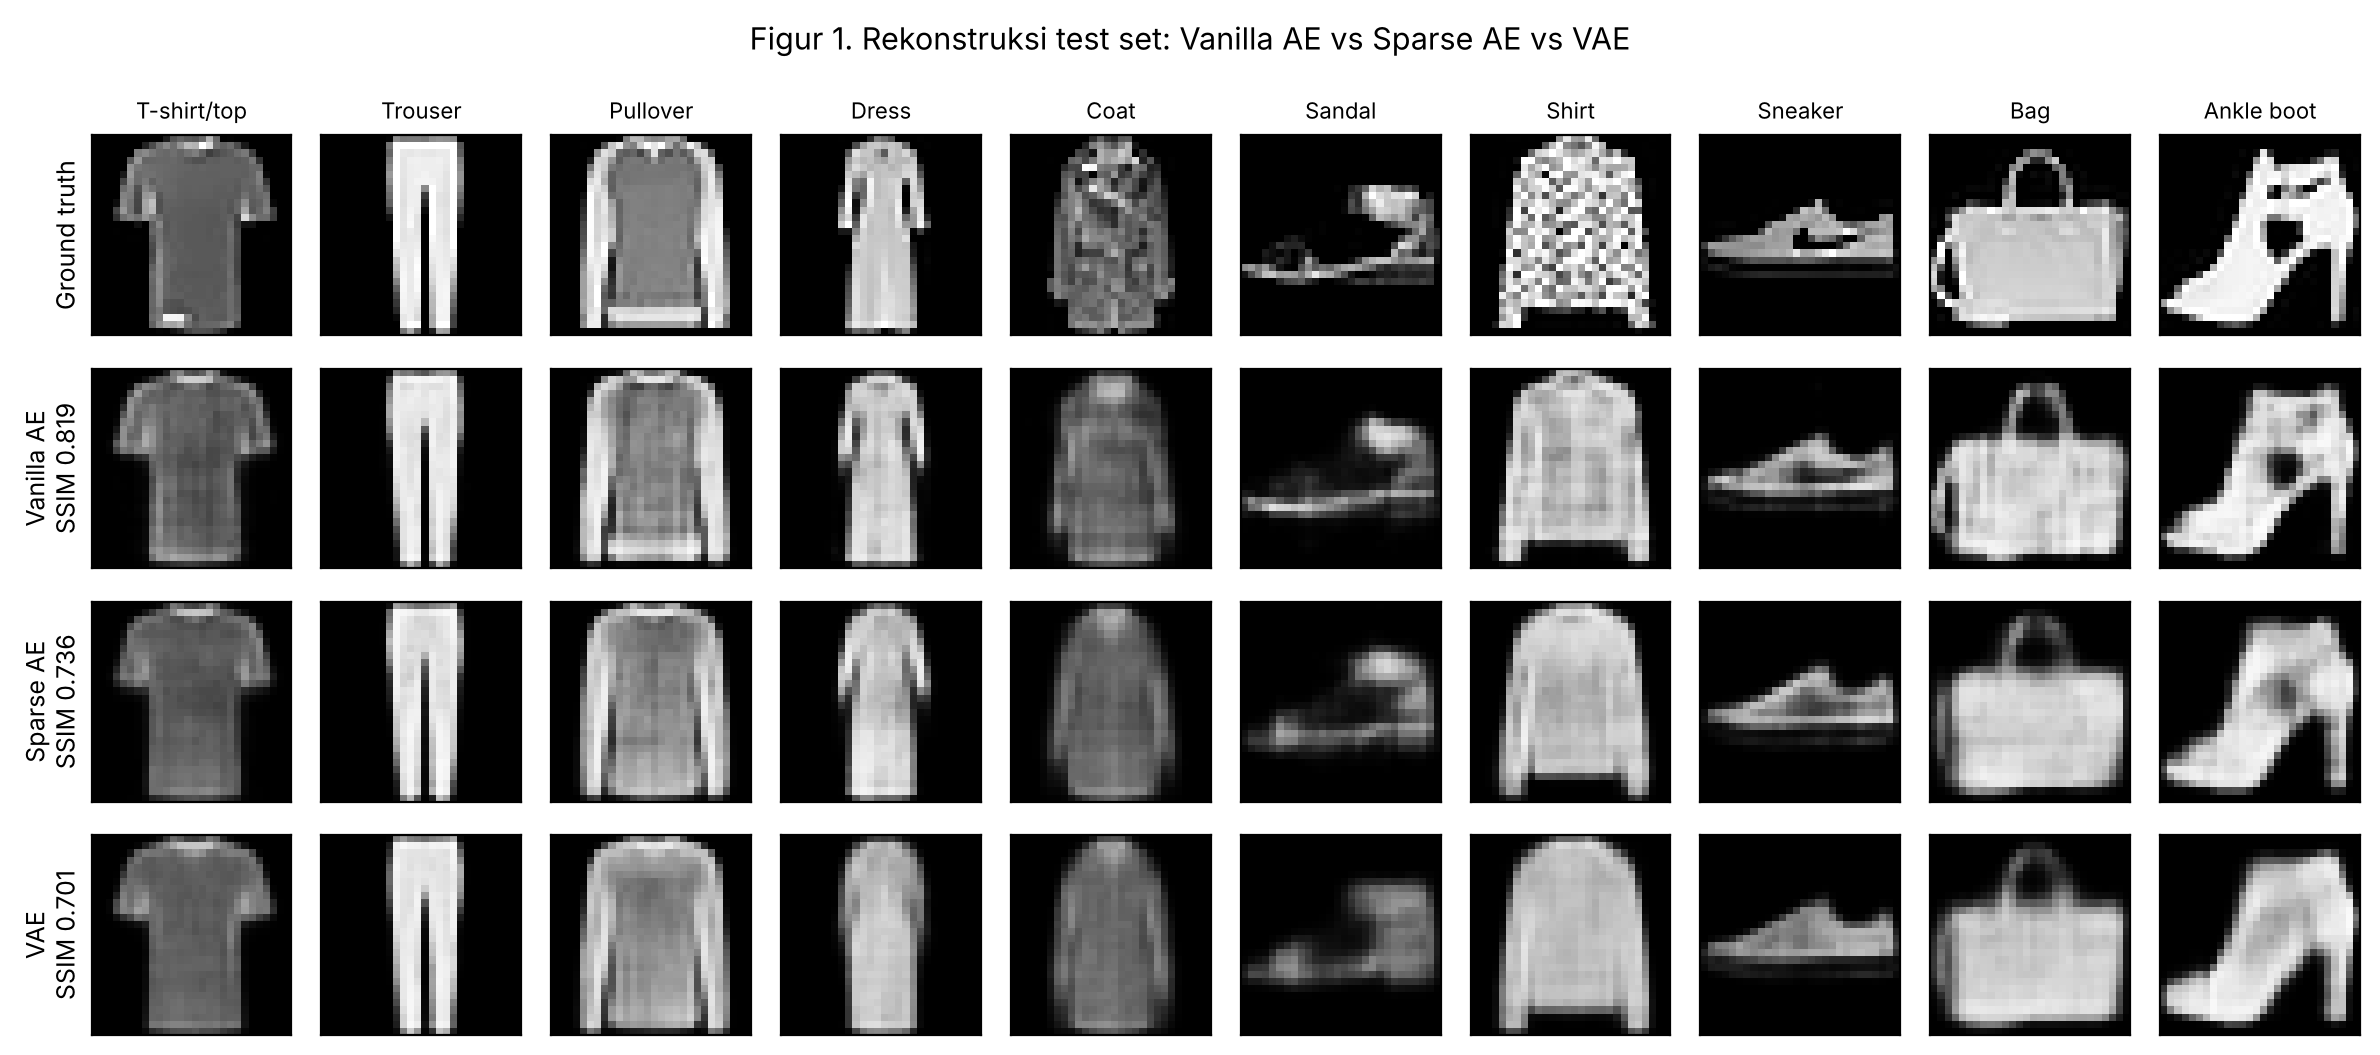

In [24]:
sel = torch.cat([torch.where(y_te == c)[0][:1] for c in range(10)])   # 1 image per kelas
rows_f1 = [("Ground truth", X_te[sel]), ("Vanilla AE", R["Vanilla AE"][sel]),
           ("Sparse AE", R["Sparse AE"][sel]), ("VAE", R["VAE"][sel])]
fig, axes = plt.subplots(4, 10, figsize=(12, 5.4))
for r, (lab, imgs) in enumerate(rows_f1):
    for c in range(10):
        ax = axes[r, c]; ax.imshow(imgs[c, 0], cmap="gray", vmin=0, vmax=1); ax.set_xticks([]); ax.set_yticks([])
        if r == 0:
            ax.set_title(CLASS_NAMES[y_te[sel[c]]], fontsize=8)
        if c == 0:
            m = recon.get(lab)
            ax.set_ylabel(lab if m is None else f"{lab}\nSSIM {m['test_ssim']:.3f}", fontsize=9)
fig.suptitle("Figur 1. Rekonstruksi test set: Vanilla AE vs Sparse AE vs VAE", fontsize=11)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig1_reconstruction.png", dpi=200); plt.show()

## 13. Figur 2 — Random generative sampling (4×4 per model)

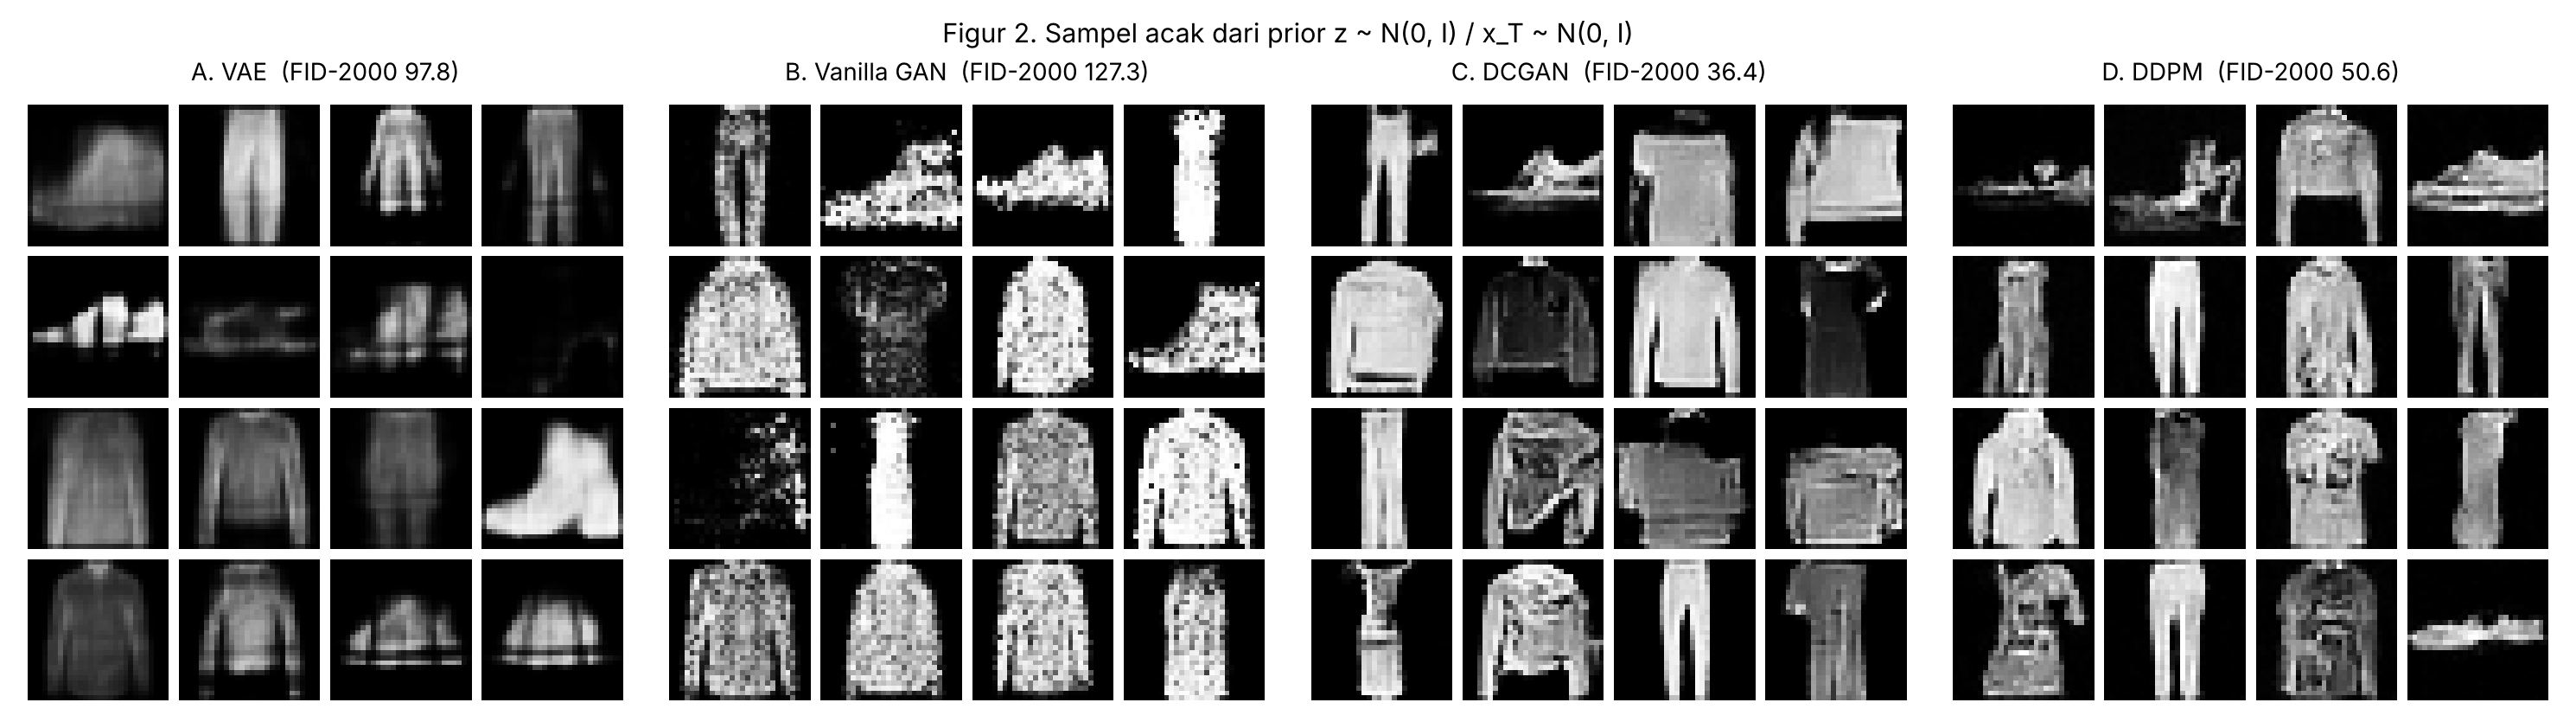

In [25]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4.3))
for ax, (lab, m) in zip(axes, [("A. VAE", "VAE"), ("B. Vanilla GAN", "Vanilla GAN"), ("C. DCGAN", "DCGAN"), ("D. DDPM", "DDPM")]):
    show_grid(ax, samples[m][:16], 4, f"{lab}  (FID-{N} {fid[m]:.1f})")
fig.suptitle("Figur 2. Sampel acak dari prior z ~ N(0, I) / x_T ~ N(0, I)", fontsize=11)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig2_random_sampling.png", dpi=200); plt.show()

## 14. Figur 3 — Bukti empiris batasan MLP Classifier

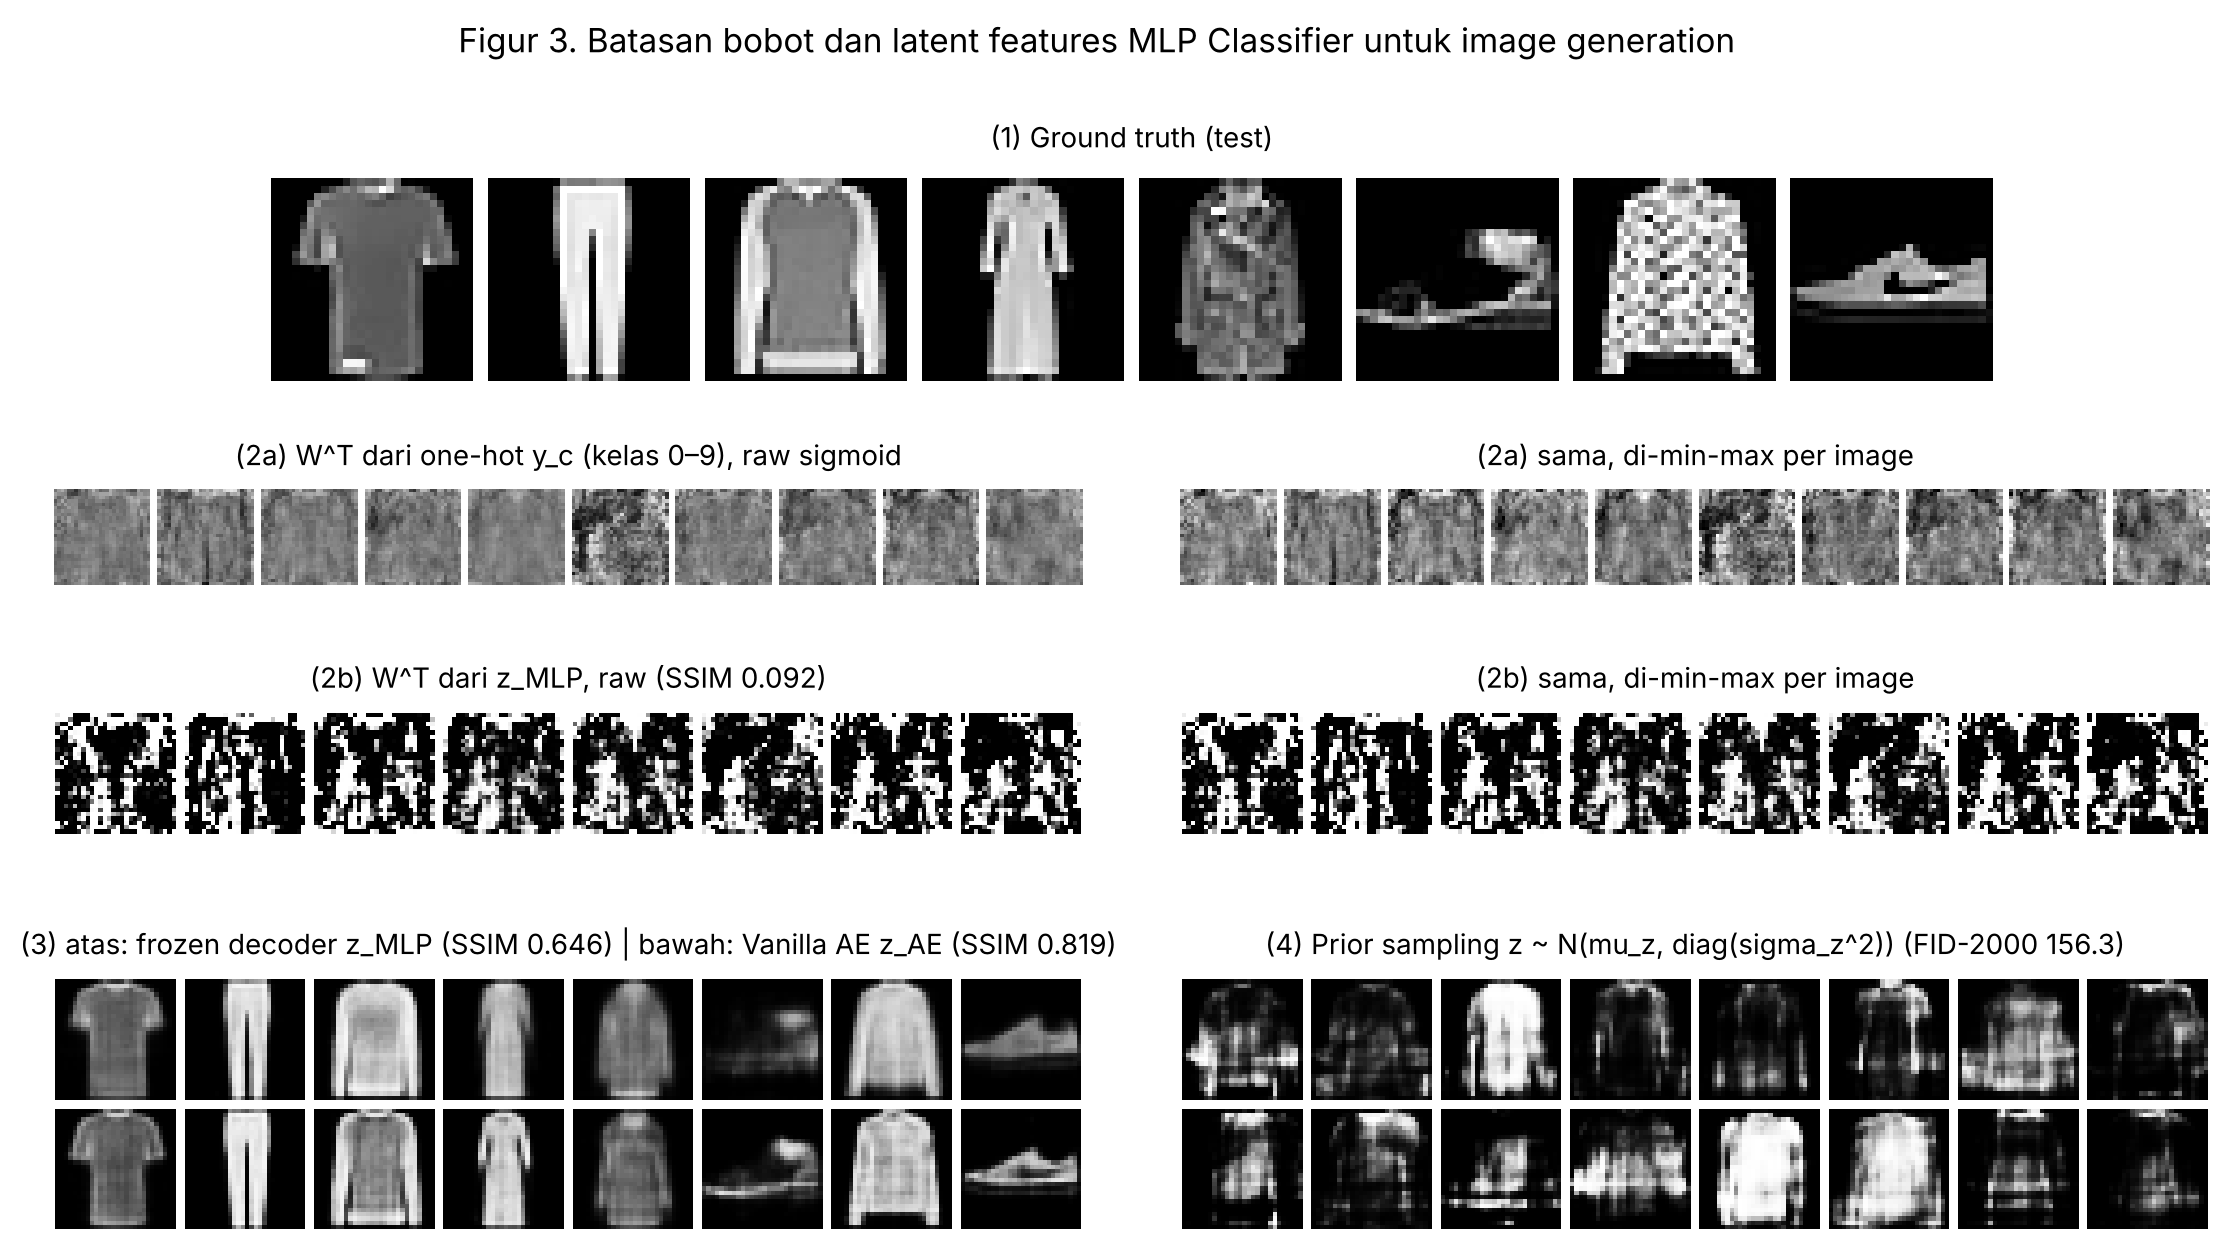

In [26]:
s8 = sel[:8]
fig = plt.figure(figsize=(14, 7.2))
gs = GridSpec(4, 2, figure=fig, height_ratios=[1.1, 0.7, 0.9, 1.6], hspace=0.3, wspace=0.08)
ax = fig.add_subplot(gs[0, :]); show_grid(ax, X_te[s8], 8, "(1) Ground truth (test)")
ax = fig.add_subplot(gs[1, 0]); show_grid(ax, X_classproj, 10,
    "(2a) W^T dari one-hot y_c (kelas 0–9), raw sigmoid")
ax = fig.add_subplot(gs[1, 1]); show_grid(ax, minmax(X_classproj), 10, "(2a) sama, di-min-max per image")
ax = fig.add_subplot(gs[2, 0]); show_grid(ax, X_latproj[s8], 8,
    f"(2b) W^T dari z_MLP, raw (SSIM {recon['MLP W^T latent projection']['test_ssim']:.3f})")
ax = fig.add_subplot(gs[2, 1]); show_grid(ax, minmax(X_latproj[s8]), 8, "(2b) sama, di-min-max per image")
ax = fig.add_subplot(gs[3, 0]); show_grid(ax, torch.cat([R["MLP frozen decoder"][s8], R["Vanilla AE"][s8]]), 8,
    f"(3) atas: frozen decoder z_MLP (SSIM {recon['MLP frozen decoder']['test_ssim']:.3f}) | "
    f"bawah: Vanilla AE z_AE (SSIM {recon['Vanilla AE']['test_ssim']:.3f})")
ax = fig.add_subplot(gs[3, 1]); show_grid(ax, samples["MLP prior sampling"][:16], 8,
    f"(4) Prior sampling z ~ N(mu_z, diag(sigma_z^2)) (FID-{N} {fid['MLP prior sampling']:.1f})")
fig.suptitle("Figur 3. Batasan bobot dan latent features MLP Classifier untuk image generation", fontsize=12)
plt.savefig(FIG_DIR / "fig3_mlp_limitations.png", dpi=200, bbox_inches="tight"); plt.show()

## 15. Figur 4 — Linear latent interpolation

Dua kelas kontras: **Trouser (1)** → **Ankle boot (9)**. AE, Sparse AE dan VAE ($\mu$) memakai encoding dua image test.
GAN dan DCGAN tidak punya encoder, jadi $z_A$ dan $z_B$ dipilih dari 1.000 sampel prior yang sampelnya paling yakin diklasifikasi sebagai Trouser dan Ankle boot oleh MLP Classifier.

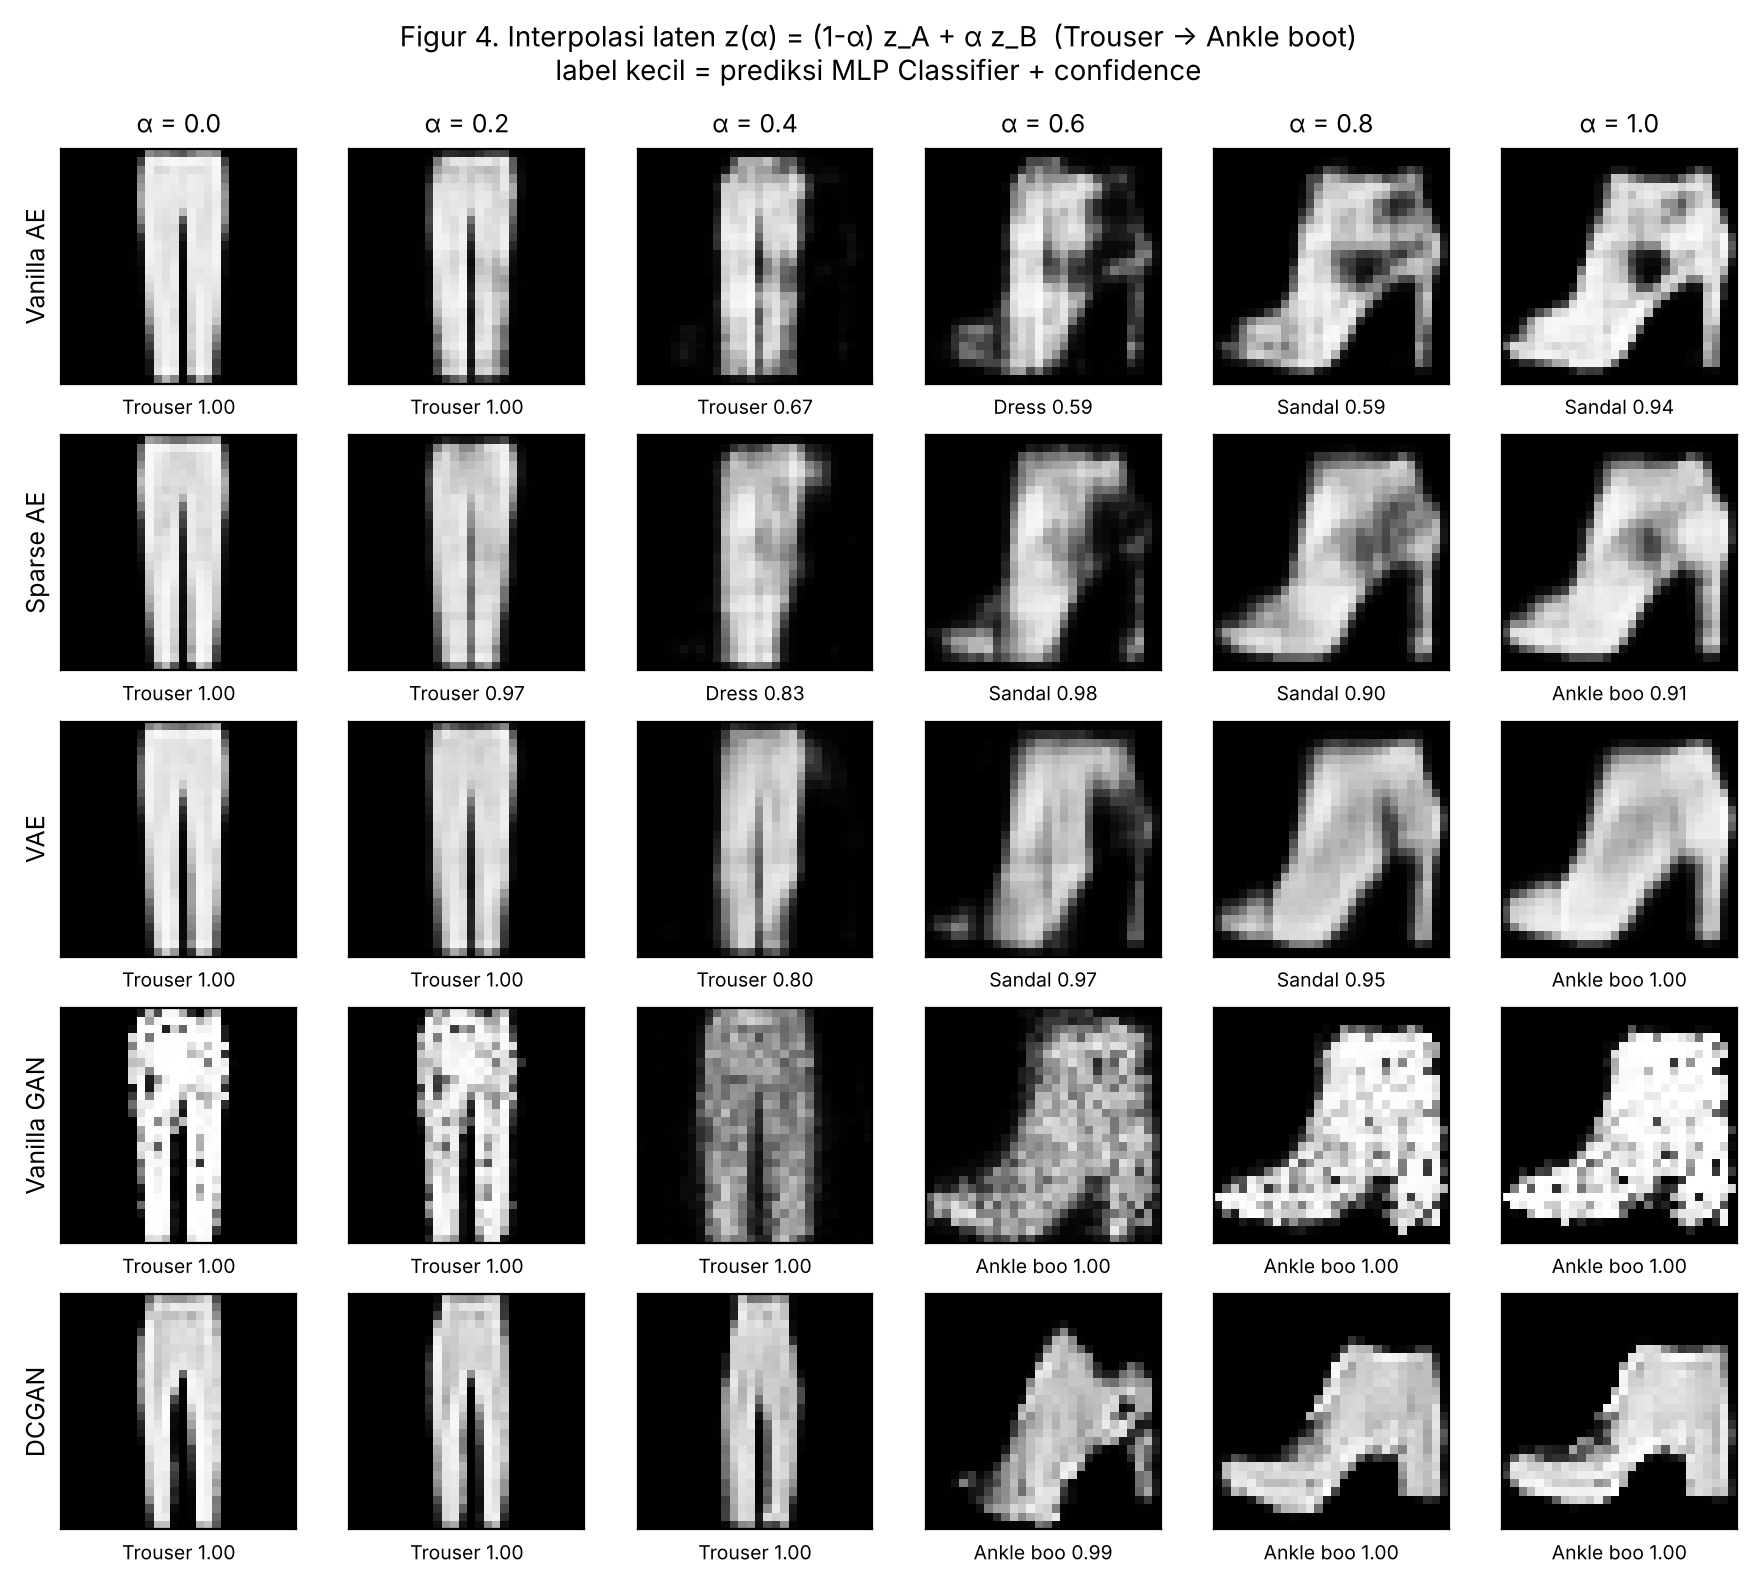

In [27]:
CA, CB = 1, 9
alphas_i = torch.tensor([0.0, 0.2, 0.4, 0.6, 0.8, 1.0])
iA, iB = torch.where(y_te == CA)[0][0], torch.where(y_te == CB)[0][0]
xA, xB = X_te[iA:iA + 1].to(device), X_te[iB:iB + 1].to(device)

def lerp(zA, zB):
    return torch.cat([(1 - a) * zA + a * zB for a in alphas_i])

@torch.no_grad()
def pick_gan_pair(G):
    z = torch.randn(1000, CFG["z_gan"], generator=gen()).to(device)
    p = F.softmax(clf(to01(G(z))), 1)
    return z[p[:, CA].argmax()][None], z[p[:, CB].argmax()][None]

with torch.no_grad():
    interp = {
        "Vanilla AE": ae.decode(lerp(ae.encode(xA), ae.encode(xB))),
        "Sparse AE": sae.decode(lerp(sae.encode(xA), sae.encode(xB))),
        "VAE": vae.decode(lerp(vae.encode(xA)[0], vae.encode(xB)[0])),
        "Vanilla GAN": to01(G_gan(lerp(*pick_gan_pair(G_gan)))),
        "DCGAN": to01(G_dc(lerp(*pick_gan_pair(G_dc)))),
    }
    interp_conf = {k: F.softmax(clf(v), 1).max(1).values.cpu().numpy() for k, v in interp.items()}

fig, axes = plt.subplots(5, 6, figsize=(9, 8))
for r, (k, imgs) in enumerate(interp.items()):
    for c in range(6):
        ax = axes[r, c]; ax.imshow(imgs[c, 0].cpu(), cmap="gray", vmin=0, vmax=1); ax.set_xticks([]); ax.set_yticks([])
        pred = CLASS_NAMES[clf(imgs[c:c + 1]).argmax().item()]
        ax.set_xlabel(f"{pred[:9]} {interp_conf[k][c]:.2f}", fontsize=7)
        if r == 0:
            ax.set_title(f"α = {alphas_i[c]:.1f}", fontsize=9)
        if c == 0:
            ax.set_ylabel(k, fontsize=9)
fig.suptitle("Figur 4. Interpolasi laten z(α) = (1-α) z_A + α z_B  (Trouser → Ankle boot)\n"
             "label kecil = prediksi MLP Classifier + confidence", fontsize=10)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig4_latent_interpolation.png", dpi=200); plt.show()

Pelengkap kuantitatif Figur 4: untuk 300 pasangan image test acak (kelas berbeda), di titik tengah $\alpha = 0.5$ dihitung
(a) jarak ke image test terdekat (MSE, makin kecil = makin "di atas manifold data") dan (b) confidence MLP Classifier.
Hanya untuk model dengan encoder (AE, Sparse AE, VAE).

In [28]:
@torch.no_grad()
def midpoint_stats(enc, dec, n_pairs=300):
    g = gen()
    a = torch.randint(0, len(X_te), (n_pairs * 3,), generator=g)
    b = torch.randint(0, len(X_te), (n_pairs * 3,), generator=g)
    keep = (y_te[a] != y_te[b]).nonzero().squeeze(1)[:n_pairs]
    a, b = a[keep], b[keep]
    zm = 0.5 * enc(X_te[a].to(device)) + 0.5 * enc(X_te[b].to(device))
    xm = dec(zm).cpu()
    ref = X_te[:3000].view(3000, -1)
    d = torch.cdist(xm.view(len(xm), -1), ref).pow(2).min(1).values / 784
    conf = F.softmax(clf(xm), 1).max(1).values
    return {"nn_mse_to_test": d.mean().item(), "clf_conf": conf.mean().item()}

midpoint = {
    "Vanilla AE": midpoint_stats(ae.encode, ae.decode),
    "Sparse AE": midpoint_stats(sae.encode, sae.decode),
    "VAE": midpoint_stats(lambda x: vae.encode(x)[0], vae.decode),
}
pd.DataFrame(midpoint).T.to_csv(OUT_DIR / "interpolation_midpoint.csv")
pd.DataFrame(midpoint).T.round(4)

,nn_mse_to_test,clf_conf
Vanilla AE,0.0272,0.6933
Sparse AE,0.0255,0.7080
VAE,0.0199,0.6487


## 16. Figur 5 — Training loss curves dan DDPM denoising trajectory

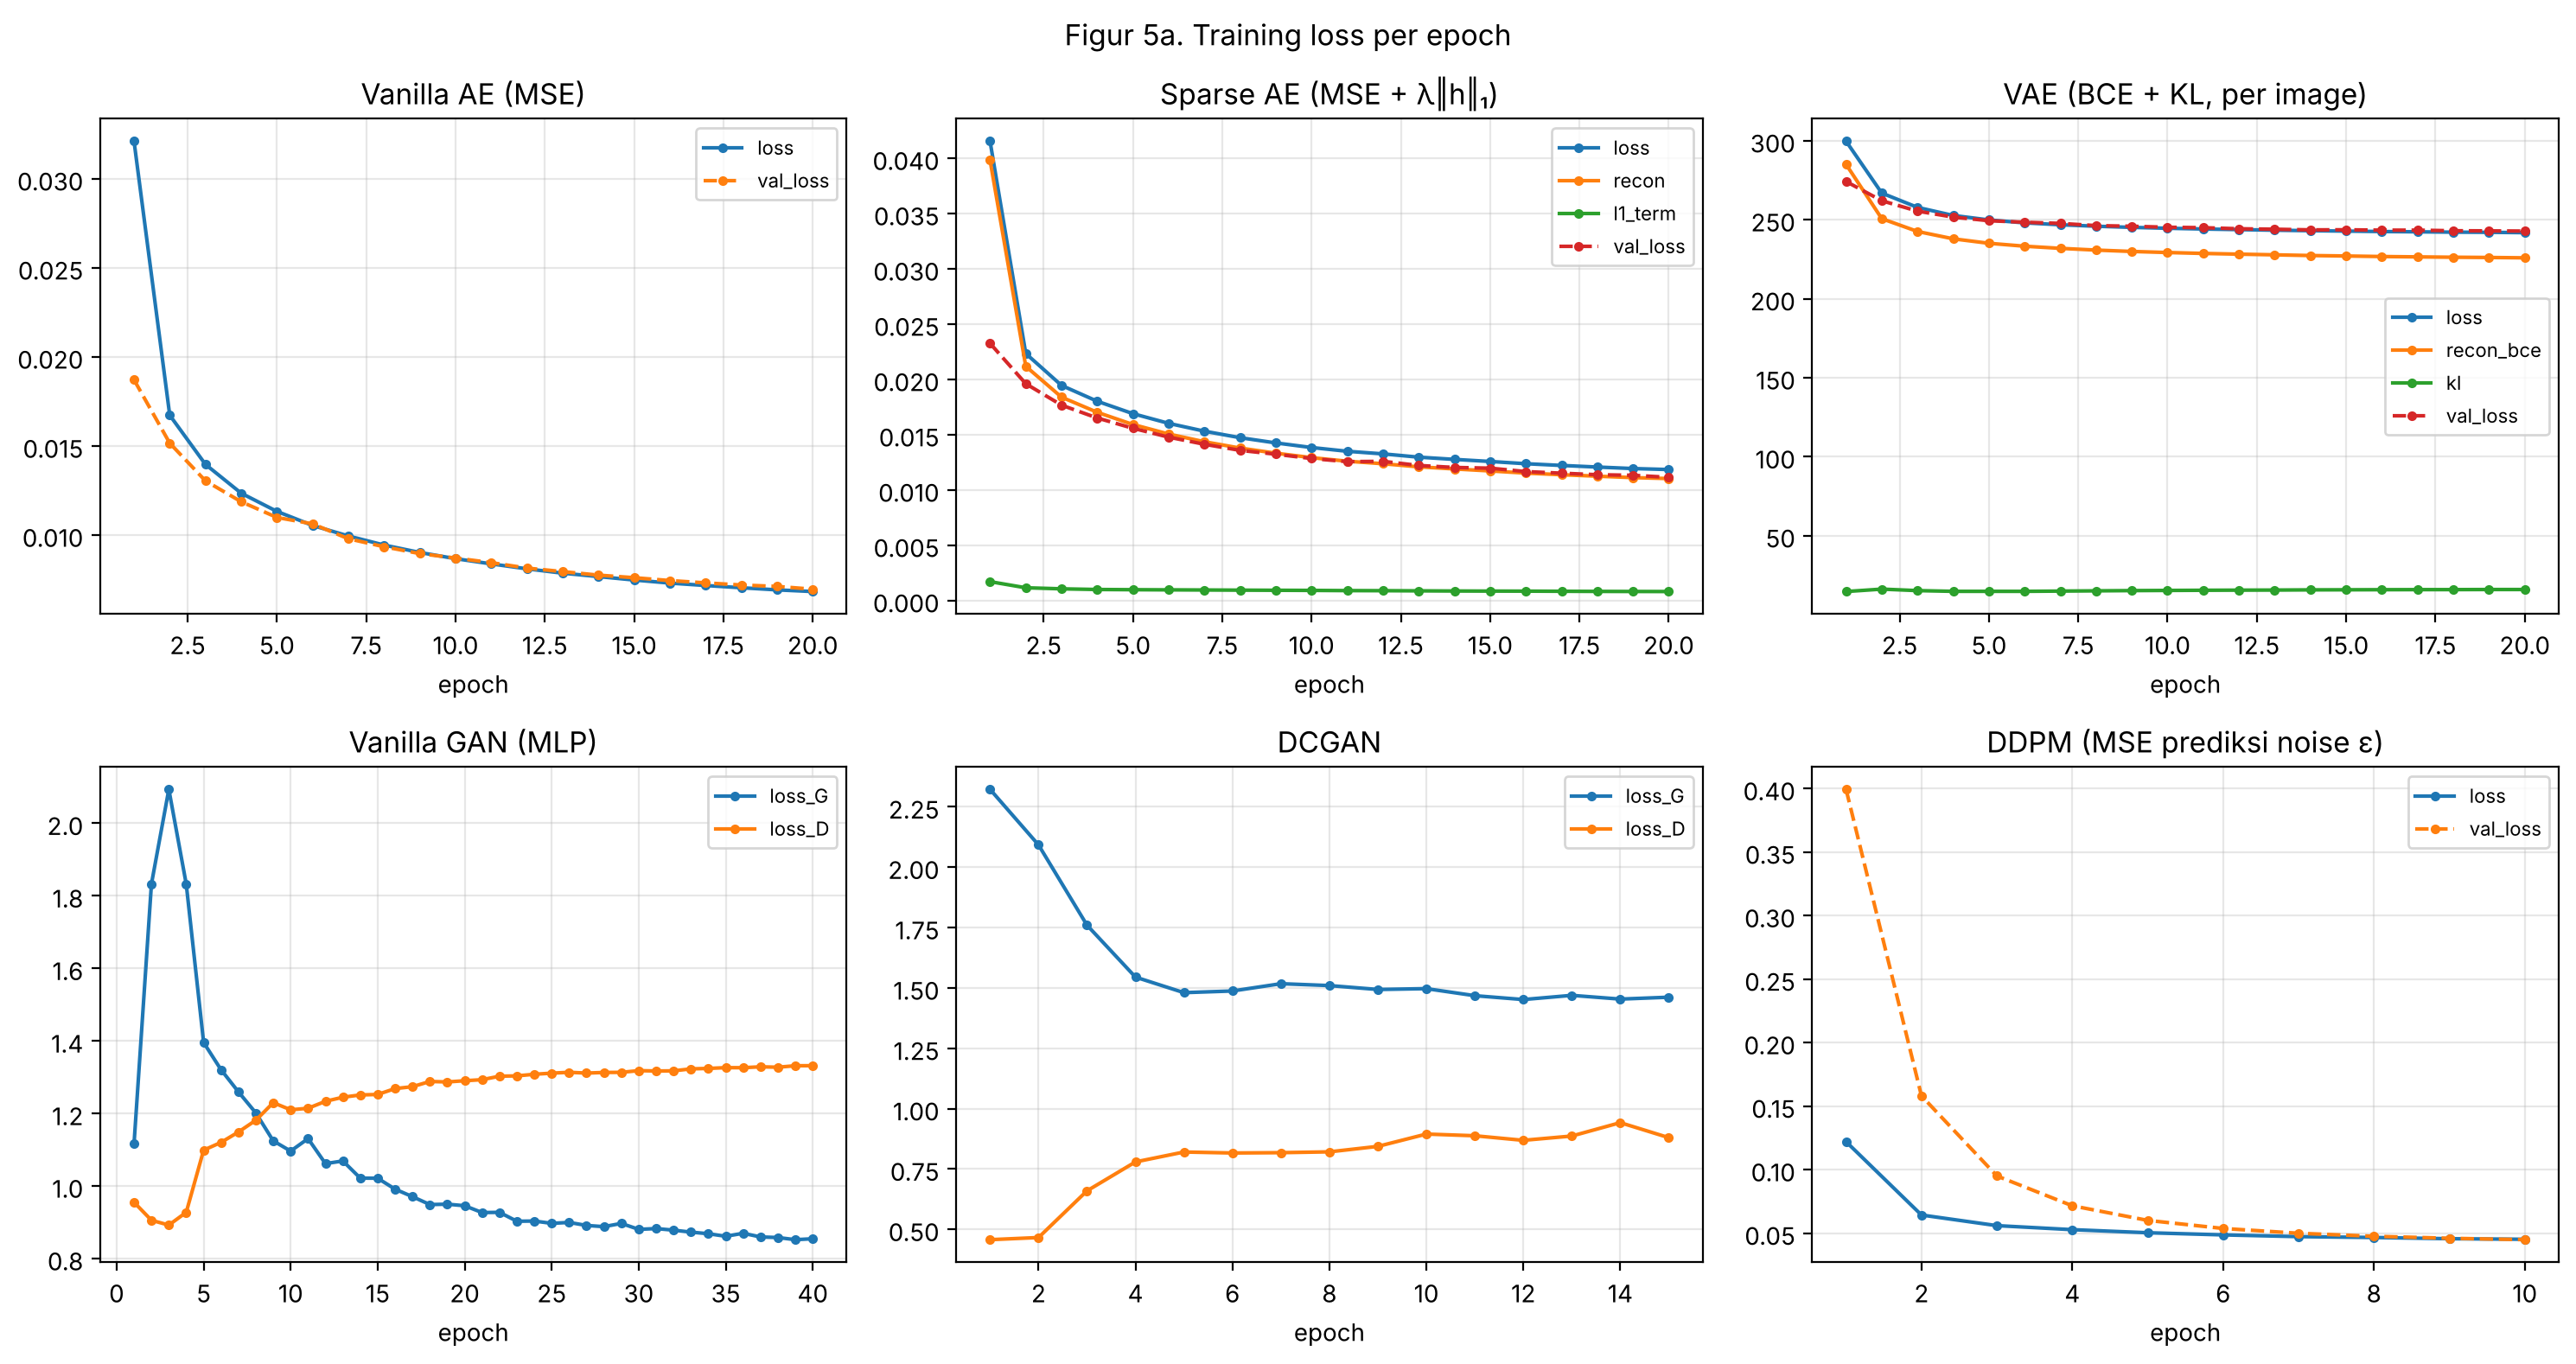

In [29]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
def plot_h(ax, key, cols, title, val=True):
    h = pd.DataFrame(HIST[key])
    for c in cols:
        ax.plot(h["epoch"], h[c], marker="o", ms=3, label=c)
    if val and "val_loss" in h:
        ax.plot(h["epoch"], h["val_loss"], "--", marker="o", ms=3, label="val_loss")
    ax.set_title(title); ax.set_xlabel("epoch"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plot_h(axes[0, 0], "ae", ["loss"], "Vanilla AE (MSE)")
plot_h(axes[0, 1], "sae", ["loss", "recon", "l1_term"], "Sparse AE (MSE + λ‖h‖₁)")
plot_h(axes[0, 2], "vae", ["loss", "recon_bce", "kl"], "VAE (BCE + KL, per image)")
plot_h(axes[1, 0], "gan", ["loss_G", "loss_D"], "Vanilla GAN (MLP)", val=False)
plot_h(axes[1, 1], "dcgan", ["loss_G", "loss_D"], "DCGAN", val=False)
plot_h(axes[1, 2], "ddpm", ["loss"], "DDPM (MSE prediksi noise ε)")
fig.suptitle("Figur 5a. Training loss per epoch", fontsize=12)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig5a_loss_curves.png", dpi=200); plt.show()

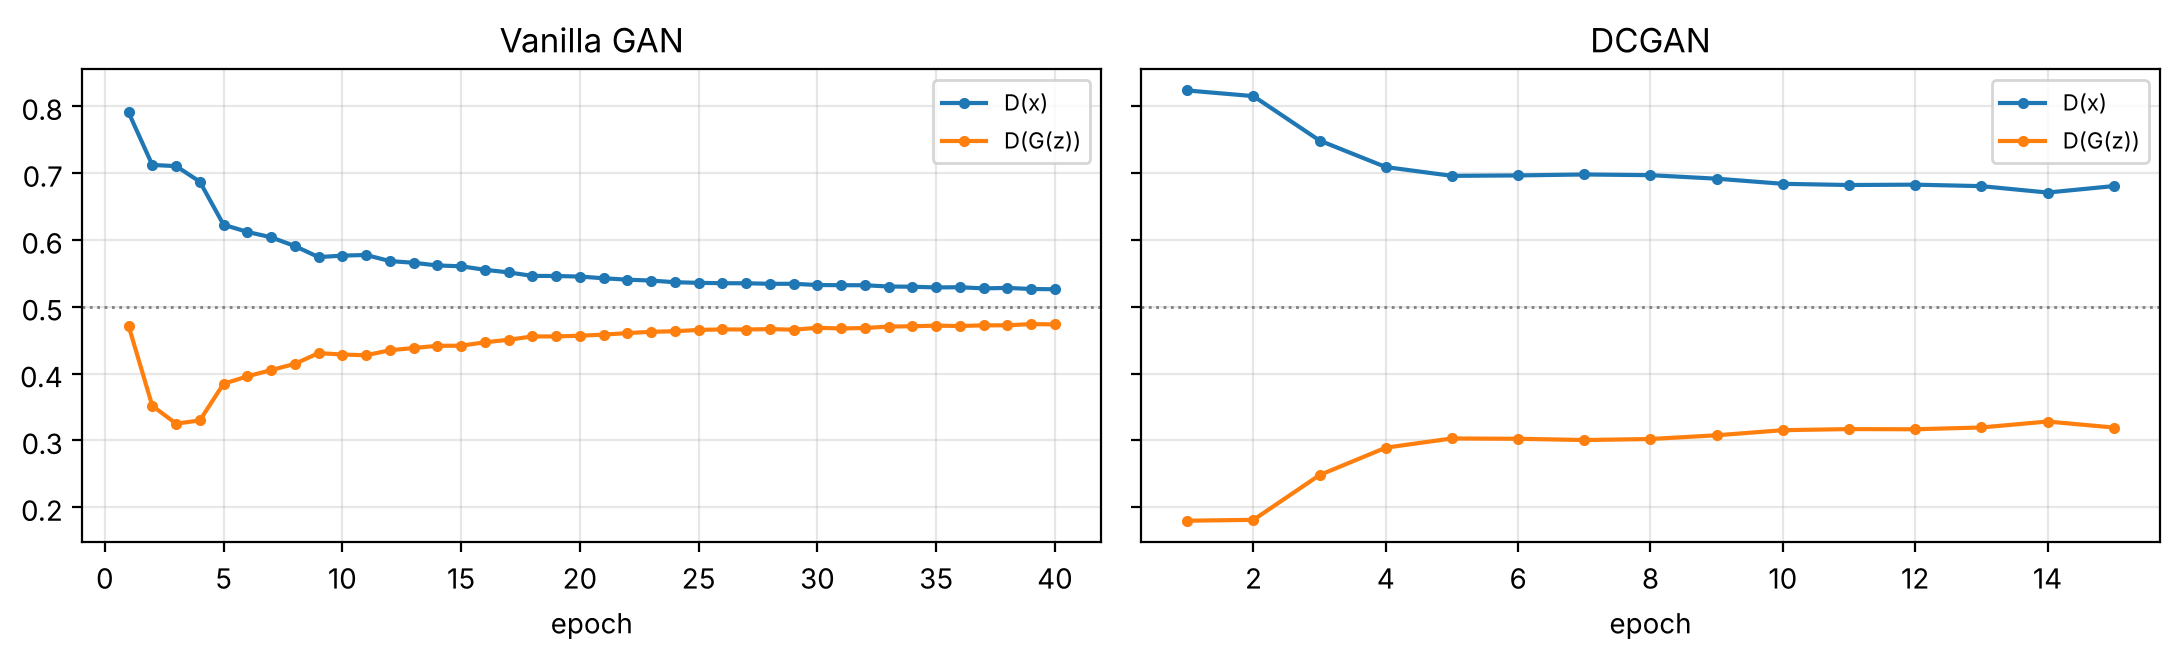

In [30]:
# dinamika D(x) dan D(G(z)) per epoch (pelengkap Q3)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharey=True)
for ax, key, t in [(axes[0], "gan", "Vanilla GAN"), (axes[1], "dcgan", "DCGAN")]:
    h = pd.DataFrame(HIST[key])
    ax.plot(h["epoch"], h["D_x"], marker="o", ms=3, label="D(x)"); ax.plot(h["epoch"], h["D_Gz"], marker="o", ms=3, label="D(G(z))")
    ax.axhline(0.5, color="gray", ls=":", lw=1); ax.set_title(t); ax.set_xlabel("epoch"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig5c_gan_D_outputs.png", dpi=200); plt.show()

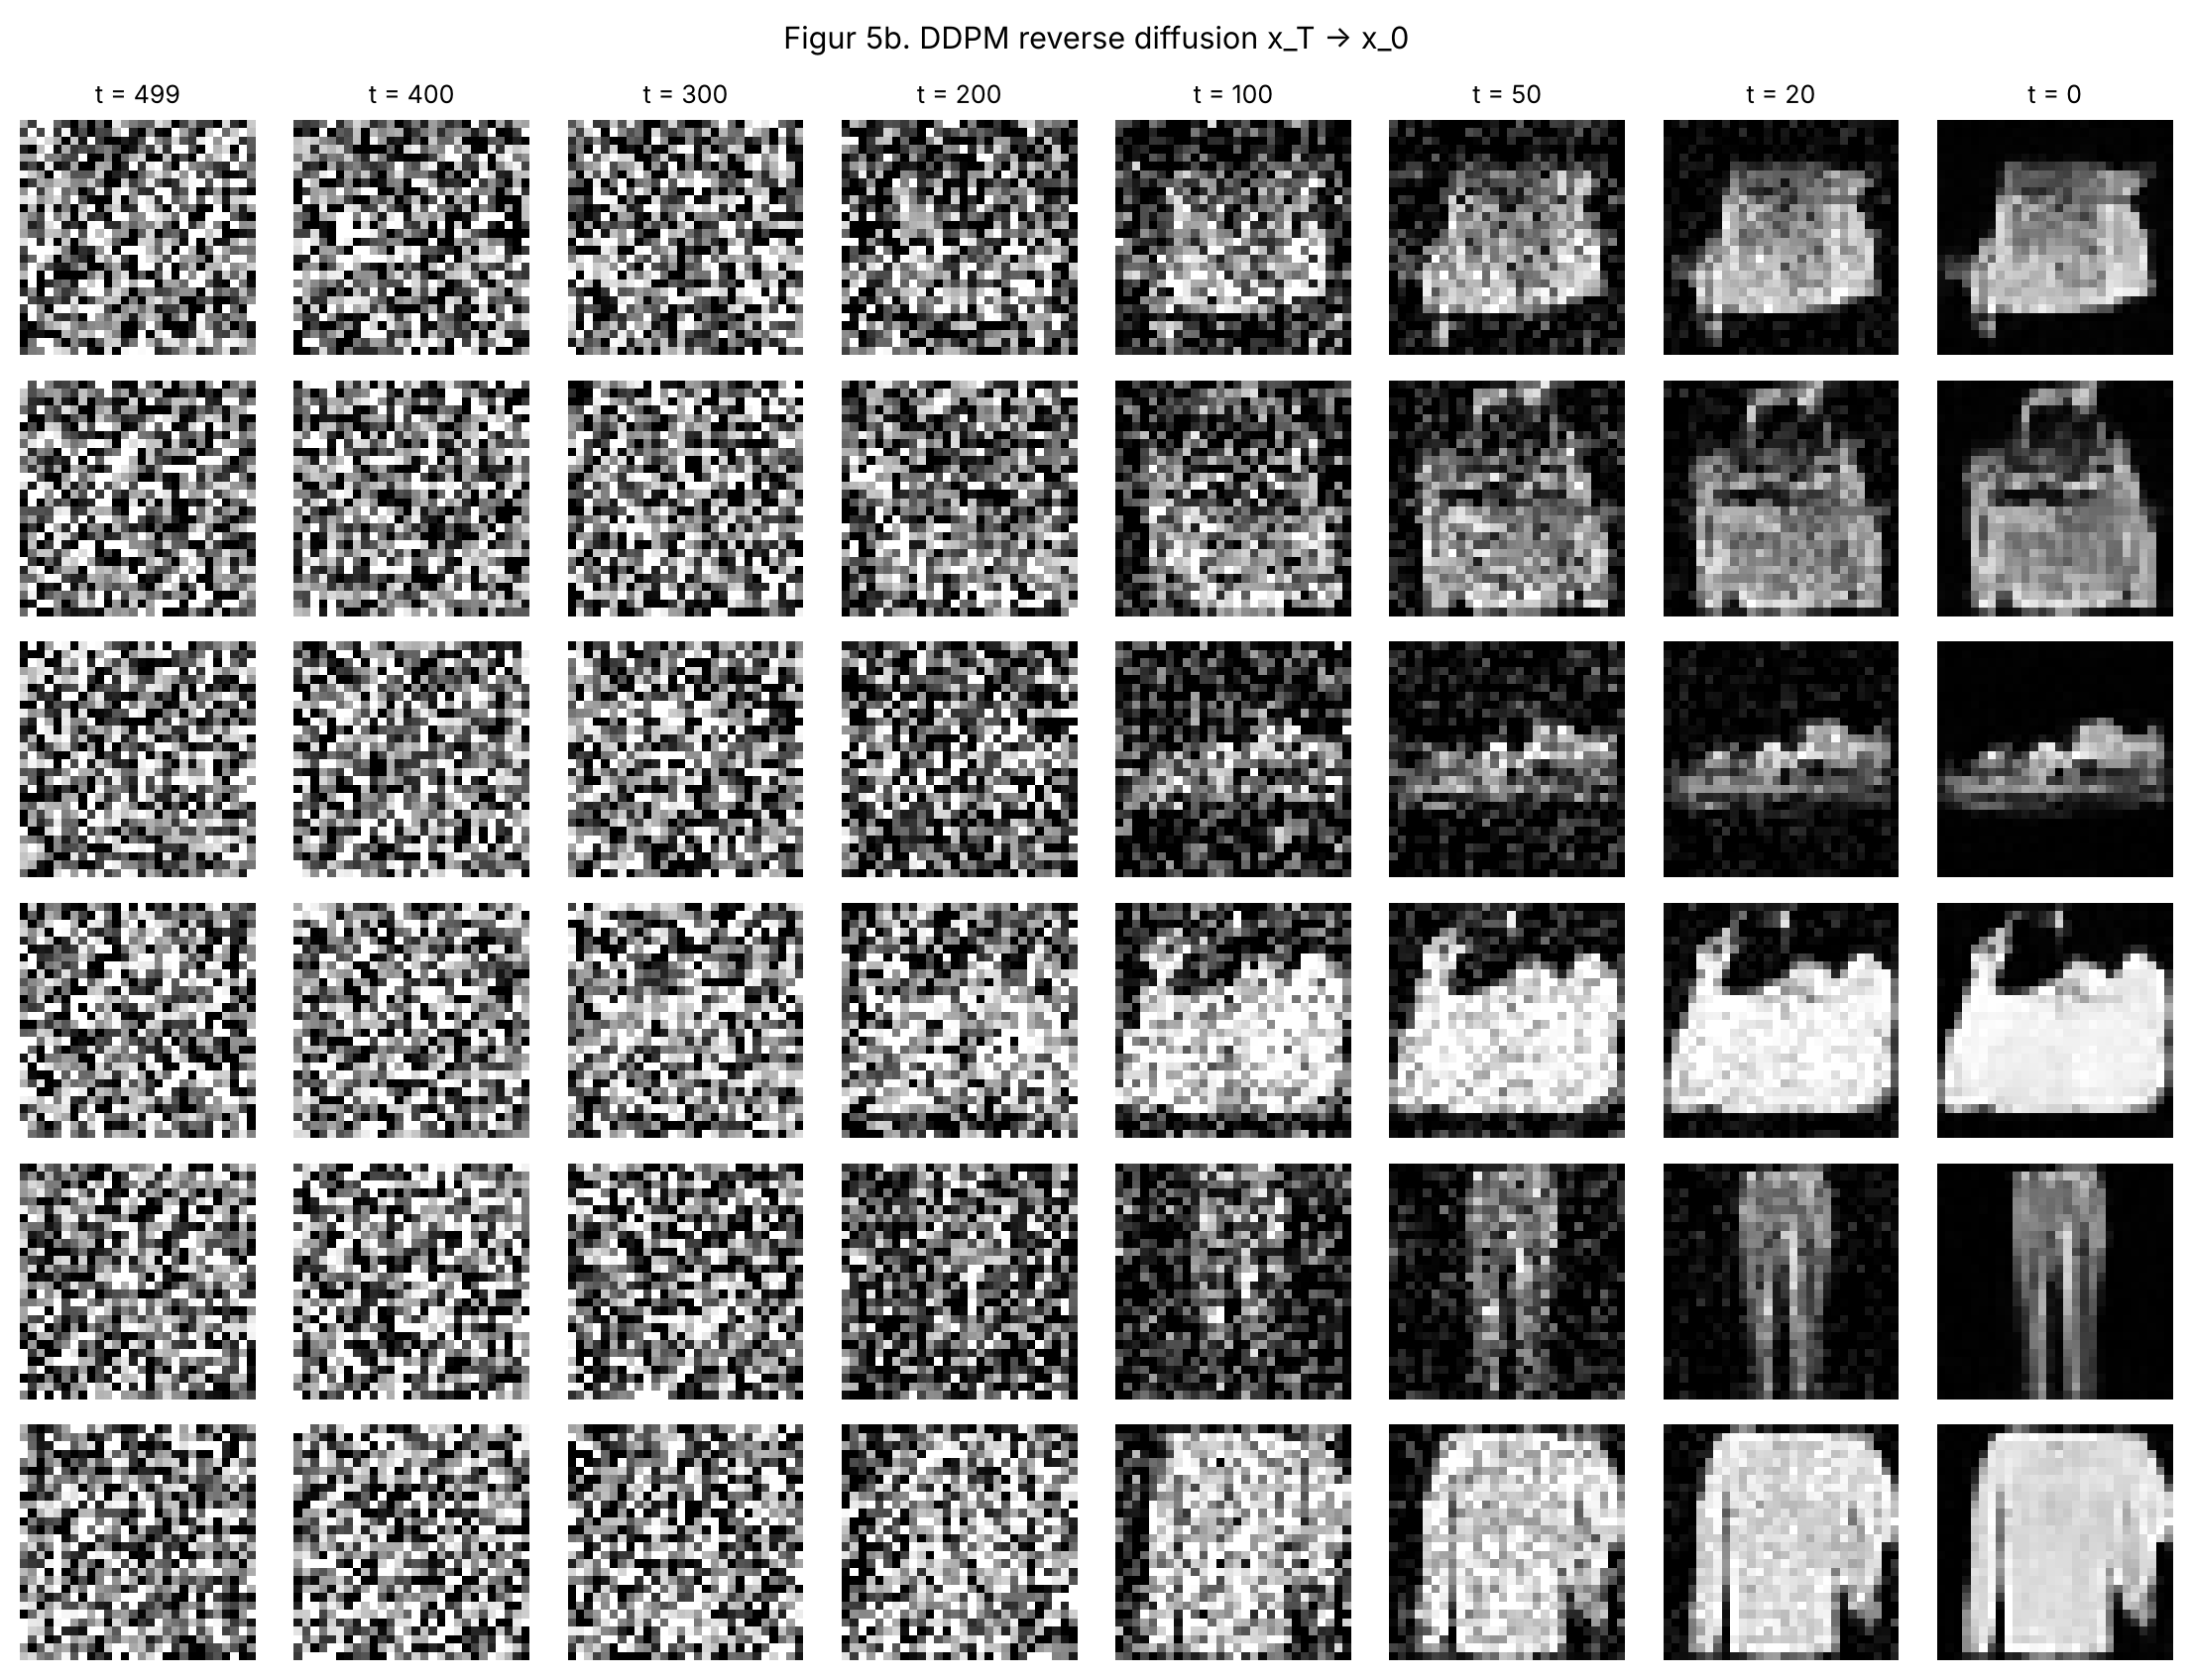

In [31]:
rec_t = sorted({T - 1, int(T * 0.8), int(T * 0.6), int(T * 0.4), int(T * 0.2), int(T * 0.1), int(T * 0.04), 0}, reverse=True)
_, traj = ddpm_sample(6, record_at=rec_t, generator=torch.Generator(device=device).manual_seed(SEED + 1))
fig, axes = plt.subplots(6, len(rec_t), figsize=(1.4 * len(rec_t), 8.6))
for c, t in enumerate(rec_t):
    for r in range(6):
        ax = axes[r, c]; ax.imshow(traj[t][r, 0], cmap="gray", vmin=0, vmax=1); ax.axis("off")
    axes[0, c].set_title(f"t = {t}", fontsize=9)
fig.suptitle("Figur 5b. DDPM reverse diffusion x_T → x_0", fontsize=11)
plt.tight_layout(); plt.savefig(FIG_DIR / "fig5b_ddpm_trajectory.png", dpi=200); plt.show()

## 17. Figur tambahan — fitur hidden layer Vanilla AE vs Sparse AE (pendukung Q2)

Baris $W_1$ encoder (256 × 784) divisualisasikan sebagai 28×28. Ditampilkan 32 unit dengan rata-rata aktivasi tertinggi, plus histogram aktivasi $h$ pada test set.

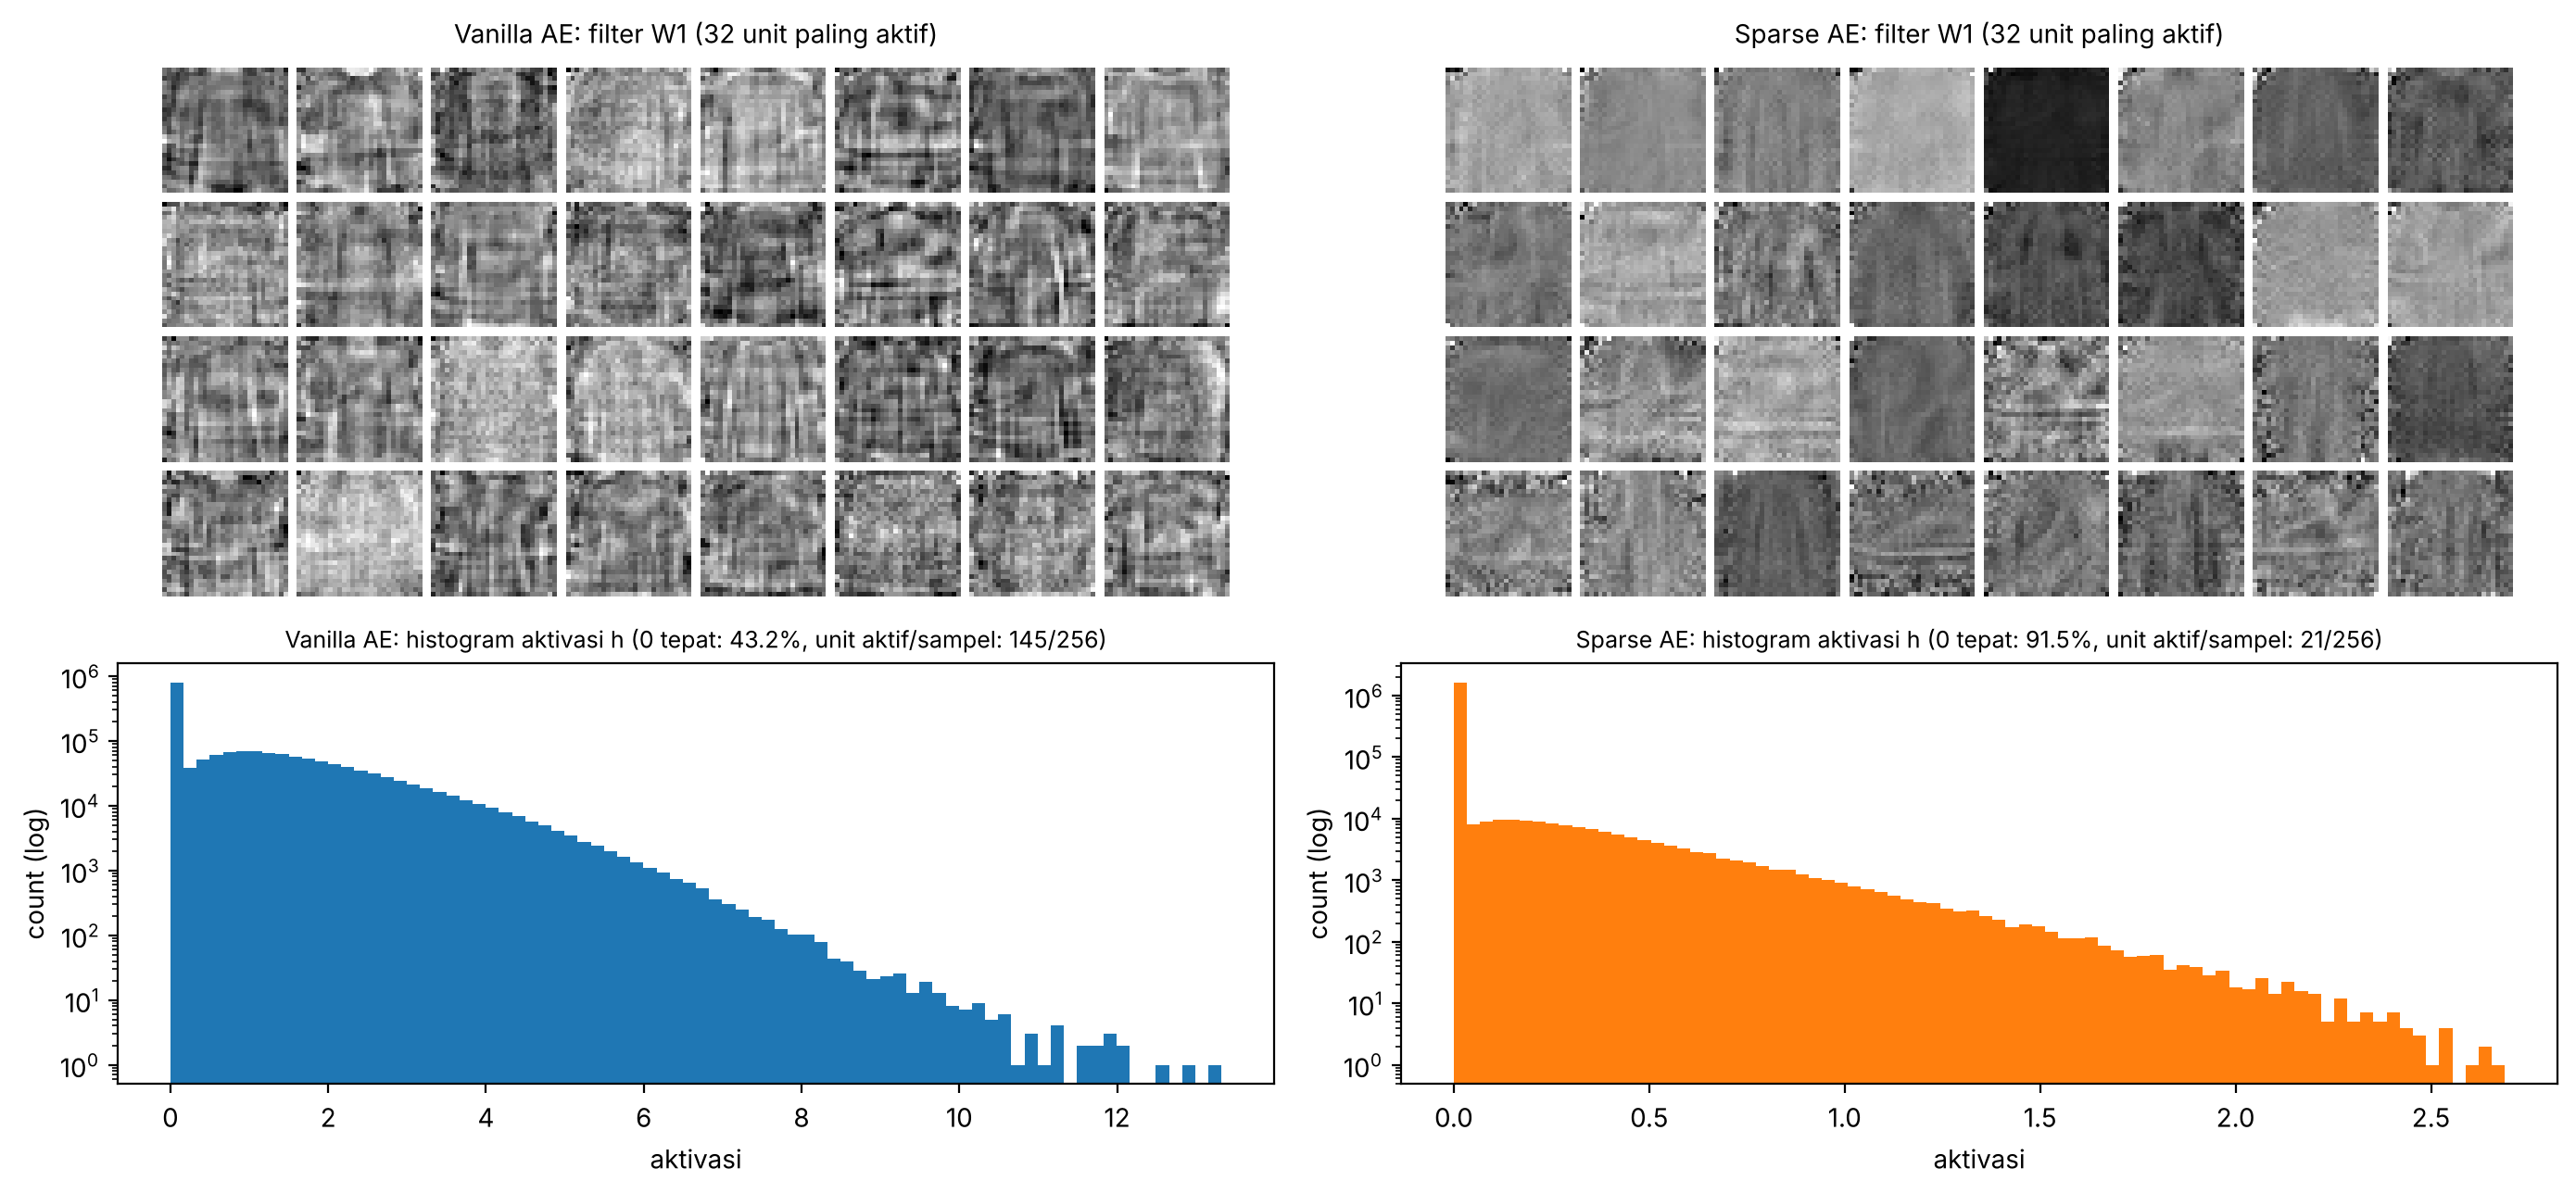

In [32]:
fig = plt.figure(figsize=(14, 6.5))
gs = GridSpec(2, 2, figure=fig, height_ratios=[1.3, 1])
for i, (lab, m, H) in enumerate([("Vanilla AE", ae, H_ae), ("Sparse AE", sae, H_sae)]):
    top = H.mean(0).argsort(descending=True)[:32]
    w = m.enc1.weight.detach().cpu()[top].view(-1, 1, 28, 28)
    ax = fig.add_subplot(gs[0, i]); show_grid(ax, minmax(w), 8, f"{lab}: filter W1 (32 unit paling aktif)")
    ax = fig.add_subplot(gs[1, i])
    ax.hist(H.flatten().numpy(), bins=80, log=True, color="C0" if i == 0 else "C1")
    st = sparsity[lab]
    ax.set_title(f"{lab}: histogram aktivasi h (0 tepat: {st['frac_zero']:.1%}, "
                 f"unit aktif/sampel: {st['mean_active_units_per_sample']:.0f}/256)", fontsize=9)
    ax.set_xlabel("aktivasi"); ax.set_ylabel("count (log)")
plt.tight_layout(); plt.savefig(FIG_DIR / "fig_extra_sparse_features.png", dpi=200); plt.show()

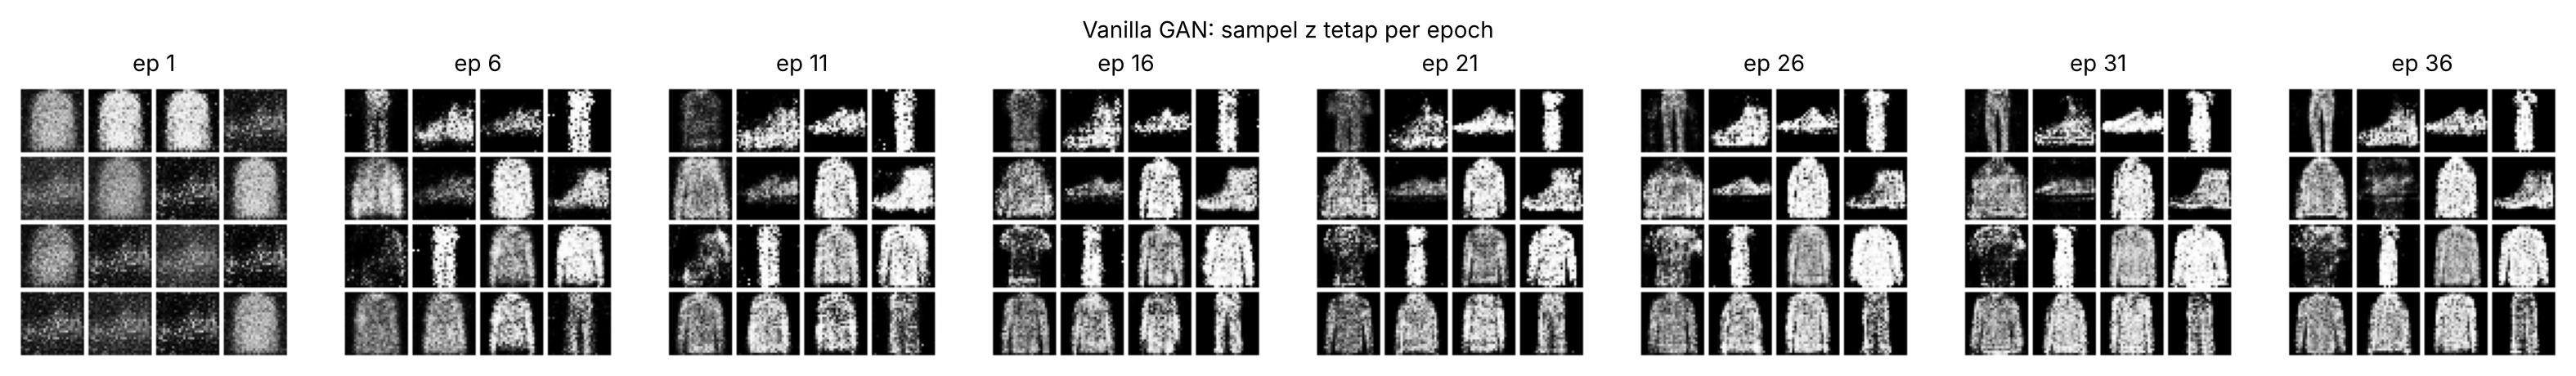

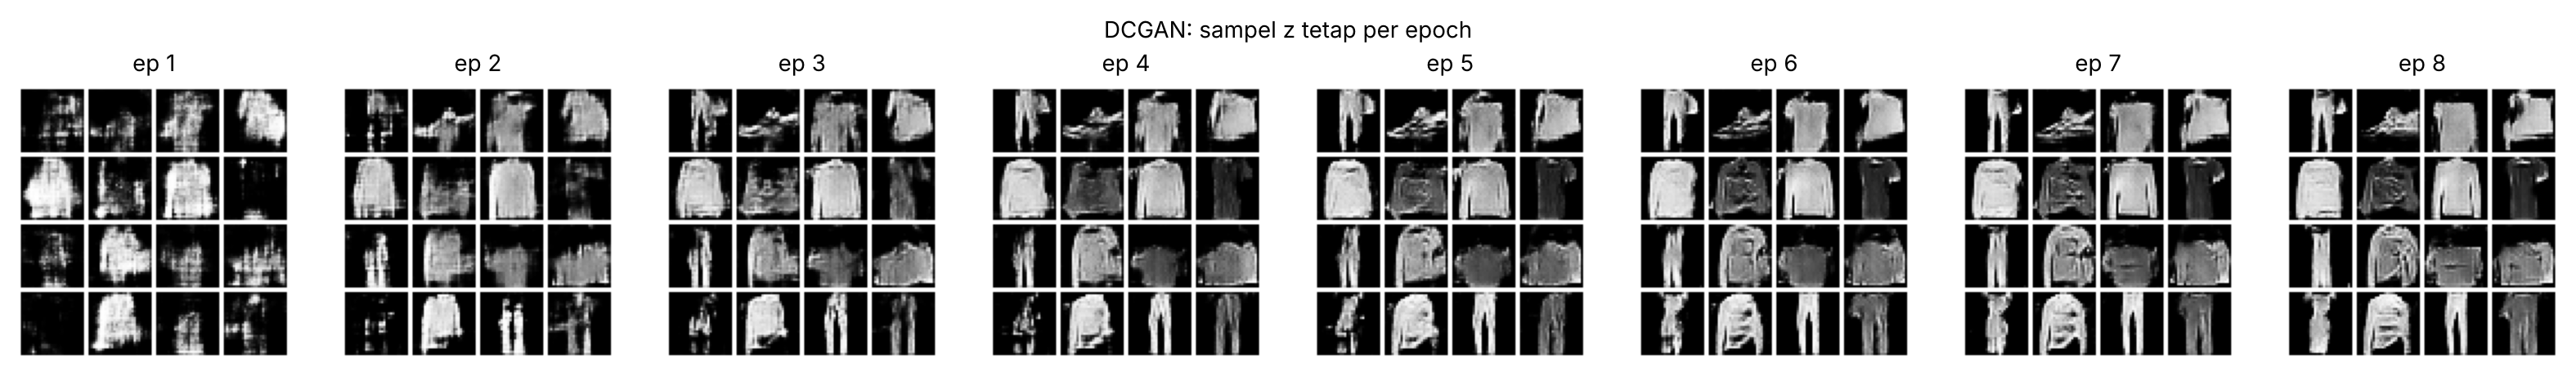

In [33]:
# progres sampel GAN/DCGAN per epoch (z tetap) - untuk melihat osilasi / mode collapse
for key, t in [("gan", "Vanilla GAN"), ("dcgan", "DCGAN")]:
    p = CKPT_DIR / f"{key}_snaps.pt"
    if p.exists():
        S = torch.load(p)
        ep = list(range(0, len(S), max(1, len(S) // 8)))[:8]
        fig, axes = plt.subplots(1, len(ep), figsize=(2 * len(ep), 2.3))
        for ax, e in zip(np.atleast_1d(axes), ep):
            show_grid(ax, S[e][:16], 4, f"ep {e + 1}")
        fig.suptitle(f"{t}: sampel z tetap per epoch", fontsize=10)
        plt.tight_layout(); plt.savefig(FIG_DIR / f"fig_extra_{key}_progress.png", dpi=150); plt.show()

## 18. Ringkasan

In [34]:
print(metrics_table.to_markdown(index=False))
with open(OUT_DIR / "metrics_table.md", "w") as f:
    f.write(metrics_table.to_markdown(index=False) + "\n\n" + stability.round(4).to_markdown(index=False)
            + "\n\n" + mlp_proof.to_markdown(index=False) + "\n")

| Model       | Dim laten                      |   Params (G+D) |   Epoch |   Train time / epoch (s) |   Latency (ms / batch 64) | Test MSE   | Test PSNR (dB)   | Test SSIM   | FID-2000           | Mode coverage (H norm)   |
|:------------|:-------------------------------|---------------:|--------:|-------------------------:|--------------------------:|:-----------|:-----------------|:------------|:-------------------|:-------------------------|
| Vanilla AE  | 64                             |         435536 |      20 |                     2.41 |                      0.46 | 0.00687    | 22.72            | 0.8189      | N/A (latent voids) | N/A                      |
| Sparse AE   | 64 (bottleneck) / 256 (sparse) |         435536 |      20 |                     2.78 |                      0.43 | 0.01103    | 20.52            | 0.7361      | N/A (latent voids) | N/A                      |
| VAE         | 64                             |         451984 |      20 |                     2.92